Binary Classification Use Case: US-Hospital Readmission

Adapting an existing notebook to a quite different use case

This notebook is a copy of "Binary Classification Use Case: Credit Scoring", see https://www.kaggle.com/code/floser/binary-classification-credit-scoring. It uses a different data set and contains the necessary code adjustments.

January 2026 / FL

<hr style="width:50%; margin-left:25% !important; margin-right:25% !important;" />
<!-- <p style="font-size:16px; font-style:italic;">Abstract:</p>-->
<span style="font-size:16px; font-style:italic;">

This Jupyter Notebook offers a hands-on tutorial on binary classification using the US diabetic readmission dataset from Kaggle. Our focus is on predicting a short time readmission, equipping actuaries with skills applicable to common insurance scenarios like churn prediction and fraud detection.

Structured in three parts, the notebook progresses from simple to advanced modeling techniques:

Part A sets a performance benchmark with an initial CatBoost model, a gradient boosting algorithm that requires minimal data preprocessing.

Part B explores logistic regression, then delves into a brief exploratory data analysis, feature engineering, and model interpretability – all essential for making informed decisions. We cover data preprocessing, including encoding, scaling, and subsampling for imbalanced data, and investigate the impact on modeling.
    
Part C is devoted to the optimization and practical application of machine learning models. It first addresses overfitting using the example of regularized logistic regression, as well as hyperparameter tuning in artificial neural networks and gradient boosting methods (CatBoost). After a comprehensive model evaluation using validation and test data, we discuss application aspects in high-risk areas and conclude by summarizing the key insights we have learned.

The appendix provides further information on CatBoost and AutoGluon.
<hr style="width:50%; margin-left:25% !important; margin-right:25% !important;" />

<p style="font-size:22px; font-weight: 500; background-color: #E6E6E6; color: black; height: 50px; line-height: 46px; padding-left: 14px;">Table of Contents</p>

Part A: Quick & Easy
- [1. Developing an Initial Baseline Machine Learning Model](#a01)

Part B: Generating Insights from Data and Modeling
- [2. Interpreting Models for Better Understanding](#a05)
- [3. Hyperparameter Optimization in CatBoost](#a09)
- [4. Data Preprocessing: Encoding, Scaling, and Subsampling](#a06)
- [5. Neural nets](#a04)
- [6. Exploratory Data Analysis and Feature Engineering](#a03)

Part C: Tuning and Applying Machine Learning Models
- [7. Logistic Regression: A Classical Approach to Classification](#a02)
- [8. Regularized Logistic Regression to Prevent Overfitting](#a07)

- [9. AutoGluon](#a10)
- [10. Model Evaluation and Application](#a11)
- [11. Key Insights into Model Performance and Binary Classification](#a12)

Appendix
- [A1. Understanding CatBoost: Additional Resources and Reading](#a14)
- [A2. Fast Execution with GPU Usage](#a15)

<br>

<h1 id="parta"
    style="font-size:22px; font-weight: 500; background-color: #E6E6E6; color: black; height: 50px; line-height: 46px; padding-left: 14px;">
    Part A: Quick & Easy
    <a class="anchor-link"
       href="#parta"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
</h1>

In Part A, we establish a baseline for model performance using a straightforward yet effective CatBoost algorithm that provides a quick insight into the predictive power of our dataset. As we progress through Parts B and C, we will explore more advanced models and optimization methods to enhance our predictions and better understand loan repayment behavior.

<h1 id="a01"
    style="font-size:18px; font-weight:bold;">
    1. Developing an Initial Baseline Machine Learning Model
    <a class="anchor-link"
       href="#a01"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

In this very first section, we will quickly build a basic machine learning model for the binary classification task of predicting loan repayment difficulties. This baseline model will serve as a benchmark for all subsequent machine learning models.

<h2 style="font-size:16px; font-weight:bold;">1.1 Setting Up the Modeling Environment</h2>

We begin by importing all required libraries, calibrating visualization parameters, and setting a random seed to ensure the reproducibility of our results.

In [1]:
import os
# Set environment variable to ignore all warnings
os.environ['PYTHONWARNINGS'] = 'ignore'

# Standard Python libraries for data analysis, scientific computing, and plotting
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import time
import re
from scipy.stats import uniform, loguniform

# Setting display options for pandas and matploblib
pd.set_option('display.max_columns', None)
COLOR_LIGHT, COLOR_DARK = '#849CBE', '#00548A'

# Scikit-learn modules for preprocessing and machine learning models
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

# Gradient boosting frameworks and logistic regression
from catboost import CatBoostClassifier
#from xgboost import XGBClassifier
#from lightgbm import LGBMClassifier
#from lightgbm.callback import log_evaluation
import statsmodels.formula.api as smf

# Explainable AI methods
import shap
shap.initjs()

# Tensorflow and Keras for artificial neural networks
import tensorflow as tf
from tensorflow.keras.utils import set_random_seed

# Ensure reproducibility
RANDOM_SEED = 2026
set_random_seed(RANDOM_SEED)

2026-07-24 08:51:15.862287: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1784883076.140699      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1784883076.220610      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1784883076.970577      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1784883076.970625      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1784883076.970628      57 computation_placer.cc:177] computation placer alr

To optimize resource usage, we adjust TensorFlow's GPU memory settings, enabling efficient computation throughout our modeling workflow.

<h2 style="font-size:16px; font-weight:bold;">1.2 Load and examine the input data</h2>

At first the mentioned dataset is loaded. To get a good first impression we randomly select a few rows to illustrate its content and its data structure.

In [2]:
# Load the dataset into a pandas DataFrame
df_raw = pd.read_csv("/kaggle/input/datasets/sarika77/diabetic-data/diabetic_data.csv")

#/kaggle/input/datasets/sarika77/diabetic-data
# Display the dimensions of the dataset (rows, columns)
print(f"Input Dataset dimensions (rows, columns): {df_raw.shape}")

# Display a random sample of 10 rows from the dataset to inspect data
df_raw.sample(n=15, random_state=RANDOM_SEED)

Input Dataset dimensions (rows, columns): (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
2660,17150268,6008589,Caucasian,Female,[70-80),?,1,1,4,4,?,Surgery-General,55,0,9,0,0,0,789,276,428,9,NaN,>8,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
28054,91817802,8568531,?,Male,[20-30),?,2,1,1,2,UN,InternalMedicine,30,0,7,0,0,0,250.11,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,NO
70909,204384492,51866145,AfricanAmerican,Female,[70-80),?,1,6,7,6,MC,?,65,3,19,0,0,1,535,280,428,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,>30
19270,68804322,63966357,Caucasian,Female,[60-70),[50-75),1,6,7,4,?,?,60,0,8,1,0,0,486,496,276,9,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,>30
82978,259065234,38190690,?,Male,[90-100),?,1,3,7,9,MC,?,65,0,28,0,0,1,507,428,496,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
71681,208276620,47871153,Caucasian,Female,[60-70),?,1,1,7,3,CP,?,42,0,16,0,0,0,682,266,250,9,NaN,NaN,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
31132,100146132,23882652,AfricanAmerican,Male,[50-60),?,1,1,7,1,?,InternalMedicine,40,1,6,0,0,1,577,571,401,5,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
65531,182740320,87180561,AfricanAmerican,Female,[70-80),?,1,1,1,1,MC,?,21,0,8,1,0,0,786,427,401,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
53316,156544170,38632050,Caucasian,Female,[80-90),?,2,3,7,6,BC,Emergency/Trauma,51,0,10,0,0,1,276,780,599,9,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
86961,276991560,84444615,Other,Male,[80-90),?,1,1,7,1,CM,?,47,0,13,0,0,2,250.8,428,427,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,NO


<h2 style="font-size:16px; font-weight:bold;">1.3 Selection of relevant patients</h2>

In [3]:
# 3a. df_raw is sorted by 'patient_nbr' and 'encounter_id' 
df_raw = df_raw.sort_values(['patient_nbr', 'encounter_id'])
df_raw.head(15)
df_raw[df_raw['patient_nbr'] == 38632050]
 

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
50335,151288230,38632050,Caucasian,Female,[80-90),?,2,1,7,5,SP,Family/GeneralPractice,19,1,8,0,0,0,331,276,276,7,NaN,>7,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
53316,156544170,38632050,Caucasian,Female,[80-90),?,2,3,7,6,BC,Emergency/Trauma,51,0,10,0,0,1,276,780,599,9,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
58697,166025856,38632050,Caucasian,Female,[80-90),?,1,3,7,7,BC,Emergency/Trauma,59,0,11,0,0,2,253,276,276,6,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
61325,171244050,38632050,Caucasian,Female,[80-90),?,2,3,7,5,BC,Emergency/Trauma,63,0,12,0,0,3,599,263,276,8,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [4]:
# 3b. For some patients there are several encounters included in the dataset. We restrict our focus to the first encounter only. 
df_raw = df_raw.groupby('patient_nbr').first().reset_index()
df_raw.shape

(71518, 50)

A look at the variable `discharge_disposition_id` shows that the data includes discharge dispositions which should not be included in a readmission analysis (e.g., death or hospice). Therefore, these discharge dispositions are excluded from the analysis.

In [5]:
# load the mapping for discharge_disposition into a pandas DataFrame 
discharge_disposition_mapping = pd.read_csv(
    "/kaggle/input/datasets/mhermanns/id-mappings-for-diabetes-dataset/id_mapping.csv", 
    skiprows = 11, 
    nrows = 30, 
    header = 0 
) 
#/kaggle/input/datasets/mhermanns/id-mappings-for-diabetes-dataset/id_mapping.csv
# Some values of the variable discharge_disposition_id - [11, 13, 14, 19, 20, 21] - indicate an outcome like death or hospice. 
# Obvioulsy we are not interested in this part of the data which is why we exclude them. 
ex = [11, 13, 14, 19, 20, 21] 
df_raw = df_raw[~df_raw.discharge_disposition_id.isin(ex)] 

# add exclusion information
id_col = discharge_disposition_mapping.columns[0]
discharge_disposition_mapping["excluded"] = (
    discharge_disposition_mapping[id_col]
    .isin(ex)
    .map({True: "Yes", False: "No"})
)

# show the mapping with full description and exclusion information
display(
    discharge_disposition_mapping.style.set_properties(
        subset=[discharge_disposition_mapping.columns[1]],
        **{'min-width': '400px', 'white-space': 'pre-wrap'}
    )
)

,discharge_disposition_id,description,excluded
0,1,Discharged to home,No
1,2,Discharged/transferred to another short term hospital,No
2,3,Discharged/transferred to SNF,No
3,4,Discharged/transferred to ICF,No
4,5,Discharged/transferred to another type of inpatient care institution,No
5,6,Discharged/transferred to home with home health service,No
6,7,Left AMA,No
7,8,Discharged/transferred to home under care of Home IV provider,No
8,9,Admitted as an inpatient to this hospital,No
9,10,Neonate discharged to another hospital for neonatal aftercare,No


ToDo: 18 und 26 auf nan
ToDo: beide anderen Variablen dazu, und ebenfalls analog auf nan
admission_type_id und admission_source_id

In [6]:
# load the mapping for admission_type into a pandas DataFrame 
admission_type_mapping = pd.read_csv(
    "../input/datasets/mhermanns/id-mappings-for-diabetes-dataset/id_mapping.csv", 
    skiprows = 1, 
    nrows = 9, 
    header = 0 
) 

# show the mapping with full description
display(admission_type_mapping)

,admission_type_id,description
0,1.0,Emergency
1,2.0,Urgent
2,3.0,Elective
3,4.0,Newborn
4,5.0,Not Available
5,6.0,NaN
6,7.0,Trauma Center
7,8.0,Not Mapped
8,NaN,NaN


In [7]:
# load the mapping for admission_source into a pandas DataFrame 
admission_source_mapping = pd.read_csv(
    "../input/datasets/mhermanns/id-mappings-for-diabetes-dataset/id_mapping.csv", 
    skiprows = 43, 
    nrows = 27, 
    header = 0 
) 

# show the mapping with full description
display(
    admission_source_mapping.style.set_properties(
        subset=[admission_source_mapping.columns[1]],
        **{'min-width': '400px', 'white-space': 'pre-wrap'}
    )
)

,admission_source_id,description
0,1,Physician Referral
1,2,Clinic Referral
2,3,HMO Referral
3,4,Transfer from a hospital
4,5,Transfer from a Skilled Nursing Facility (SNF)
5,6,Transfer from another health care facility
6,7,Emergency Room
7,8,Court/Law Enforcement
8,9,Not Available
9,10,Transfer from critial access hospital


<h2 style="font-size:16px; font-weight:bold;">1.4 Generating diagnosis groups</h2>

In this section we define a function designed to group different diagnoses which indicate a similar medical condition. 
This procedure is supposed to reduce the complexity of the data. The grouping scheme is induced by: Table 2 in Strack et al. (2014).

In [8]:
# Define function
def icd9_group(icd):
    if pd.isna(icd):
        return np.nan

    icd = str(icd).strip()

    # ? Codes (missing)
    if icd == "?":
        return np.nan

    # E–V Codes
    if icd.startswith(("E", "V")):
        return "Other"

    # Numeric part (before decimal)
    try:
        code = int(icd.split(".")[0])
    except ValueError:
        return "Other"

    # ---- Group definitions ----
    if (390 <= code <= 459) or code == 785:
        return "Circulatory"

    elif (460 <= code <= 519) or code == 786:
        return "Respiratory"

    elif (520 <= code <= 579) or code == 787:
        return "Digestive"

    elif code == 250:
        return "Diabetes"

    elif 800 <= code <= 999:
        return "Injury"

    elif 710 <= code <= 739:
        return "Musculoskeletal"

    elif (580 <= code <= 629) or code == 788:
        return "Genitourinary"

    elif 140 <= code <= 239:
        return "Neoplasms"

    elif (
        code in {780, 781, 784}
        or (790 <= code <= 799)
        or (240 <= code <= 279 and code != 250)
        or (680 <= code <= 709)
        or code == 782 or
        (1 <= code <= 139)
        or (290 <= code <= 319)
        or (280 <= code <= 289)
        or (320 <= code <= 359)
        or (630 <= code <= 679)
        or (360 <= code <= 389)
        or (740 <= code <= 759)
    ):
        return "Other"

    else:
        return "Other"

# Apply function
for col in ["diag_1", "diag_2", "diag_3"]:
    df_raw[col + "_group"] = df_raw[col].apply(icd9_group)

# Check function: Values of the primary diagnosis (compare with table 2 in article) 
df_raw.diag_1_group.value_counts()

diag_1_group
Circulatory        21384
Other              12122
Respiratory         9486
Digestive           6487
Diabetes            5748
Injury              4694
Musculoskeletal     4064
Genitourinary       3440
Neoplasms           2538
Name: count, dtype: int64

<h2 style="font-size:16px; font-weight:bold;">1.5 Define target</h2>

In [9]:
# 2c. We now approach the defintion of the target variable
df_raw.readmitted.value_counts()

readmitted
NO     41474
>30    22222
<30     6277
Name: count, dtype: int64

In [10]:
# To sharpen our focus we willingly exclude those encounters which have led to a readmission after more than 30 days
df_raw = df_raw[(df_raw['readmitted'] != '>30')]
df_raw.shape

(47751, 53)

In [11]:
# 2d. Now we´re ready to set our target variable and eliminate some fields which won´t be needed anymore
df_raw['TARGET'] = df_raw.readmitted.apply(lambda x: 1 if x == '<30' else 0)
df_raw = df_raw.drop(columns=['readmitted','encounter_id','patient_nbr'])

Subsequently, we will assess the balance of the dataset by plotting the distribution of the 'TARGET' variable.

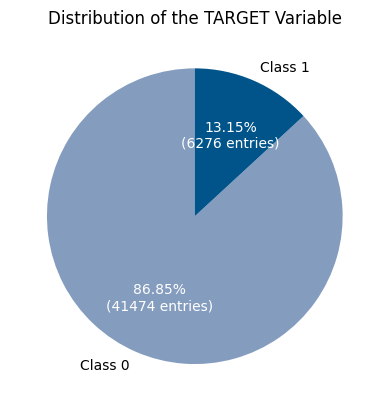

In [12]:
# Count the occurrences of each unique value in the 'TARGET' column
target_counts = df_raw['TARGET'].value_counts()

# Calculate the total number of entries
total_entries = len(df_raw['TARGET'])

# Define a custom formatting function for the pie chart labels
def custom_autopct(pct):
    absolute = int(pct/100.*total_entries)
    return "{:.2f}%\n({:d} entries)".format(pct, absolute)

# Create a pie chart to visualize the distribution of classes in the 'TARGET' column
pie_chart, _, autotexts = plt.pie(target_counts, labels=target_counts.index.map({0: 'Class 0', 1: 'Class 1'}),
                                  autopct=custom_autopct, startangle=90,
                                  colors=[COLOR_LIGHT, COLOR_DARK], wedgeprops={'edgecolor': 'none'})

# Set the color of the autopct texts to white
for autotext in autotexts:
    autotext.set_color('white')

# Plot the pie chart
plt.title('Distribution of the TARGET Variable')
plt.show()

The pie chart illustrates a clear imbalance in the distribution of the dependent variable `TARGET`: The critical class `1` appears significantly less frequently than class `0`.

Accurate classification of rare events is challenging in imbalanced datasets, such as the one observed with the `TARGET` variable. In these scenarios, it is advisable to use the area under the receiver operating characteristic curve (AUC) rather than accuracy as the performance metric. While accuracy reflects overall prediction correctness, it can be misleading by not accounting adequately for the performance on minority classes. In contrast, AUC evaluates a model's ranking ability, which is particularly relevant in distinguishing between classes in imbalanced contexts. AUC measures the trade-off between the true positive rate and the false positive rate, providing a more nuanced understanding of a model's capacity to identify rare events. We will look at this in more detail in Part B.

<h2 style="font-size:16px; font-weight:bold;">1.6 Define categories and replace missing categorical values</h2>

In [13]:
# Find columns whose names end with "_id"
id_columns = [col for col in df_raw.columns if col.endswith("id")]

# Convert their types to 'object'
df_raw[id_columns] = df_raw[id_columns].astype('object')

While many machine learning (ML) tools require the more complex data preparation steps described in Part B, CatBoost, the ML tool of our choice, only requires the minimal data preparation implemented below by replacing missing categorical values with a predefined value. 

In [14]:
# Identify categorical features by data type 'object'
categorical_features = list(df_raw.select_dtypes(include=['object']).columns)

# Compute the number of unique values for each categorical feature and reset the index to make 'Feature Names' a column
categorical_feature_counts = df_raw[categorical_features].nunique().reset_index()

# Set the column names to 'Feature' and 'Number of Unique Values'
categorical_feature_counts.columns = ['Categorical Feature', 'Number of Unique Values']

# Sort the DataFrame by 'Number of Unique Values' in descending order
categorical_feature_counts.sort_values(by='Number of Unique Values', ascending=False, inplace=True)

# Display the resulting DataFrame
display(categorical_feature_counts.style.hide(axis='index'))

Categorical Feature,Number of Unique Values
diag_3,724
diag_2,678
diag_1,661
medical_specialty,67
discharge_disposition_id,21
payer_code,18
admission_source_id,17
age,10
weight,9
diag_1_group,9


In [15]:
# define "?" and "Unknown/Invalid" as NA
df_raw[categorical_features] = df_raw[categorical_features].replace(
    ["?", "Unknown/Invalid", "nan", "NaN", "Not Available"], np.nan
)

/tmp/ipykernel_57/272232592.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_raw[categorical_features] = df_raw[categorical_features].replace(


Next, we identify those categorical features that contain missing values and calculate the percentage of values that are absent.

In [16]:
# Define a function that returns a DataFrame with features containing missing values
# and the percentage of missing values for each of these features
def missing_values_percentage(data):
    # Calculate percentages and create a DataFrame
    nan_percentages = data.isna().sum() * 100 / len(data)
    missing_values_df = pd.DataFrame({
        'Categorical Feature': nan_percentages.index, 
        'Missing Percent': nan_percentages.values
    })
    # Format the 'Missing Percent' column as a percentage string with two decimal places
    missing_values_df['Missing Percent'] = missing_values_df['Missing Percent'].apply(lambda x: f'{x:.2f}%')
    # Filter out features without missing values and sort by percentage
    missing_values_df = missing_values_df[missing_values_df['Missing Percent'] != '0.00%']
    missing_values_df.sort_values(by='Missing Percent', ascending=False, inplace=True)
    return missing_values_df

# Calculate the proportion of missing values for the categorical features
missing_values_df = missing_values_percentage(df_raw[categorical_features])

# Display the resulting DataFrame without the index using the new recommended Styler.hide method
missing_values_df_styled = missing_values_df.style.hide(axis='index')
display(missing_values_df_styled)

Categorical Feature,Missing Percent
weight,96.92%
max_glu_serum,95.38%
A1Cresult,80.06%
medical_specialty,47.27%
payer_code,42.67%
race,3.11%
diag_3,2.02%
diag_3_group,2.02%
diag_2,0.51%
diag_2_group,0.51%


To address missing values in categorical columns without imputing data or dropping records, we will assign instances of missing data to a distinct category, `__missingValue__`. This strategy allows our machine learning algorithms to process missingness as an informative feature in its own right, thereby maintaining the dataset's full breadth and the integrity of input for modeling.

In [17]:
# Replace missing values with a new category '__missingValue__' in all categorical columns
df_raw[categorical_features] = df_raw[categorical_features].fillna('__missingValue__')


<h2 style="font-size:16px; font-weight:bold;">1.7 Partitioning data into training, validation, and test subsets</h2>

When we train a machine learning classifier, we don't just want it to learn to model the training data, or simply memorisz them (ML models can be large and complex enough to do this). We want the model to generalize to data it hasn't seen before. Therefore, model performance is usually measured against a held-out test set consisting of examples that have never been seen before. For consistency with upcoming model optimization strategies, we randomly divide our dataset into three parts:

* <u>Training set</u>: 70% of examples used for model training
* <u>Validation set</u>: 15% to validate our models after the training and possibly decide on changes
* <u>Test set</u>: 15% for the final measurement of the generalization performance of all relevant models (see [Section 11](#a11))

This division allows for effective model training, hyperparameter tuning to prevent overfitting, and unbiased evaluation of performance on new, unseen data.

In [18]:
# Constants for data split ratios
TRAIN_RATIO = 0.7
VAL_TEST_RATIO = 0.5  # Splitting the remaining 30% equally into validation and test

# Separate the features (X) and the target (y)
X_raw = df_raw.drop(columns=['TARGET'], axis=1)
y = df_raw['TARGET']

# Split the dataset into a training set and a combined validation and test set
X_raw_train, X_raw_val_test, y_train, y_val_test = train_test_split(X_raw, y, train_size=TRAIN_RATIO, random_state=RANDOM_SEED)

# Further split the combined validation and test set into separate validation and test sets
X_raw_val, X_raw_test, y_val, y_test = train_test_split(X_raw_val_test, y_val_test, test_size=VAL_TEST_RATIO, random_state=RANDOM_SEED)

# Verify the dimensions of the training, validation, and test sets by displaying (rows, columns)
print(f"Training set dimensions (rows, columns):   {X_raw_train.shape}")
print(f"Validation set dimensions (rows, columns):  {X_raw_val.shape}")
print(f"Test set dimensions (rows, columns):        {X_raw_test.shape}")

Training set dimensions (rows, columns):   (33425, 50)
Validation set dimensions (rows, columns):  (7163, 50)
Test set dimensions (rows, columns):        (7163, 50)


For the three samples, check the mean values and standard deviations of the TARGET variable `y`:

In [19]:
# Calculate TARGET mean and std for each set
stats = pd.DataFrame({
    'Mean': [y_train.mean(), y_val.mean(), y_test.mean()],
    'Standard Deviation': [y_train.std(), y_val.std(), y_test.std()]
}, index=['Train', 'Validation', 'Test']).round(4)

print(stats)

              Mean  Standard Deviation
Train       0.1304              0.3367
Validation  0.1336              0.3402
Test        0.1343              0.3410


These randomly generated differences in the mean values of the TARGET variables appear small at first, but can have an impact on the final evalution, as we will see in [Section 11](#a11).

<h2 style="font-size:16px; font-weight:bold;">1.8 Training a default CatBoost classifier (baseline model)</h2>

We proceed by applying the CatBoost model to our prepared dataset, utilizing the default settings for a straightforward evaluation without hyperparameter tuning.

In [20]:
# Start timer to calculate the running time of training the CatBoost model
start_time = time.time()

# Fit the CatBoostClassifier on the training data
CB1 = CatBoostClassifier(eval_metric='AUC', random_seed=RANDOM_SEED)
CB1.fit(X_raw_train, y_train, cat_features=categorical_features, logging_level='Silent')

# Calculate and print the running time in seconds
elapsed_time_CB1 = time.time() - start_time
print(f"Elapsed time (sec): {elapsed_time_CB1:.2f}")

Elapsed time (sec): 129.30


To showcase the breadth of customization available for refining the CatBoost model, we present a complete list of hyperparameters and their default settings.

In [21]:
# Display all model hyperparameters in a DataFrame
hyperparams_list = [(k, v) for k, v in CB1.get_all_params().items()]
hyperparams_df = pd.DataFrame(hyperparams_list, columns=['Hyperparameter', 'Value'])
display(hyperparams_df.style.hide(axis='index'))

Hyperparameter,Value
nan_mode,Min
eval_metric,AUC
combinations_ctr,"['Borders:CtrBorderCount=15:CtrBorderType=Uniform:TargetBorderCount=1:TargetBorderType=MinEntropy:Prior=0/1:Prior=0.5/1:Prior=1/1', 'Counter:CtrBorderCount=15:CtrBorderType=Uniform:Prior=0/1']"
iterations,1000
sampling_frequency,PerTree
fold_permutation_block,0
leaf_estimation_method,Newton
random_score_type,NormalWithModelSizeDecrease
counter_calc_method,SkipTest
grow_policy,SymmetricTree


In order to gain preliminary insights into the trained model's behavior, we visualize the built-in feature importances that highlight the most influential features driving the predictions.

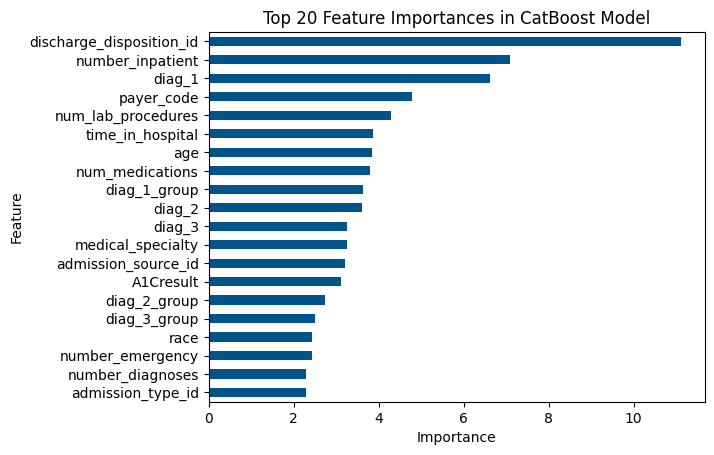

In [22]:
# Extract the 15 most important features and create a Series for plotting
feature_importances = pd.Series(CB1.feature_importances_, index=X_raw_train.columns).nlargest(20)

# Plot the feature importances
feature_importances.plot(kind='barh', color=COLOR_DARK)
plt.gca().invert_yaxis()
plt.title('Top 20 Feature Importances in CatBoost Model')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

The feature importance plot above reveals that the most influential predictors are external information sources, specifically `discharge_disposition_id`, `diag_1`,`number_inpatient` and `payer_code`, which exert a significant impact. 

We proceed to evaluate the performance of our CatBoost model against the validation set, using the area under the Receiver Operating Characteristic Curve (AUC) as our chosen evaluation metric (see above).

In [23]:
# Calculate the AUC score using the model's prediction probabilities for the positive class
auc_CB1 = roc_auc_score(y_val, CB1.predict_proba(X_raw_val)[:, 1])

# Print the validation AUC
print(f'The validation AUC of the CatBoost model with standard hyperparameters is: {auc_CB1:.6f}')

The validation AUC of the CatBoost model with standard hyperparameters is: 0.715503


In summary, Part A established a solid baseline for our binary classification task utilizing a CatBoost model with minimal data preparation and without adjustment of its hyperparameters. This is already a complex model, but it is very easy to build and is known for its high predictive power with default parameters. This benchmark serves as a reference point to assess the value of the more elaborate models constructed in the subsequent sections.

<h1 id="partb"
    style="font-size:22px; font-weight: 500; background-color: #E6E6E6; color: black; height: 50px; line-height: 46px; padding-left: 14px;">
    Part B: Generating Insights from Data and Modeling
    <a class="anchor-link"
       href="#partb"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
</h1>

<img src="https://i.postimg.cc/WzVpcvDT/DALL-E-2024-02-01-15-34-28-sitting-and-standing-data-scientists-big-bulb-and-screen-wide-window.png" style="float: center; width: '100%'; max-width: '800px'">

Part B focuses on refining our machine learning strategy to extract valuable insights. We start with a thorough examination of logistic regression, a cornerstone of actuarial analytics, in its classical unregularized form. We then move on to a targeted exploratory data analysis and feature engineering to enhance our models' predictive power. An emphasis on model explainability is also included. To set the stage for the advanced modeling techniques in Part C, we wrap up with key preprocessing activities: encoding, scaling, and subsampling.

<h1 id="a02"
    style="font-size:18px; font-weight:bold;">
    2. Interpreting Models for Better Understanding
    <a class="anchor-link"
       href="#a02"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

This section is devoted to explainability of the models presented so far. In the first subsection, we take a look at the logistic regression model from [Section 3](#a02) and demonstrate its intrinsical interpretability. In the second subsection, we utilize a model-agnostic explainable AI method (i.e., an explainable AI method that is applicable to any machine learning method) to gain insights into the CatBoost model from [Section 1](#a04).

<h2 style="font-size:16px; font-weight:bold;">2.1 Intrinsical interpretability of logistic regression</h2>

Logistic regression is an intrinsically interpretable machine learning method because it directly models the probability of the outcome variable based on the input features. This allows for easy interpretation of the effect of each input feature on the outcome, as well as the overall model performance. In particular, the sign and the magnitude of the coefficients demonstrate the influence and the importance of the features. Additionally, the coefficients of logistic regression can be easily translated into odds ratios, making it easy to communicate the impact of each feature on the outcome.

We illustrate the ideas above on the particular logistic regression model from [Section 3](#a02). As shown in the mentioned section, the coefficient of the feature `number_inpatient` is `0.6256`. From this value, we can conclude:
* As the coefficient of `number_inpatient` is positive, higher values of this feature will result in higher output probabilities.
* By interpreting the coefficient of `number_inpatient` as the change in log odds, the value `0.6256` shows that an increase of this feature by `1` results in an output probability changed by the factor `1.8693`.

<h2 style="font-size:16px; font-weight:bold;">2.2 Explaining any machine learning model with SHAP</h2>

In the course of this subsection, we illustrate how the model-agnostic explainable AI method SHAP will give insights into the previously created CatBoost model from [Section 1](#a04). SHAP (<u>SH</u>apley <u>A</u>dditive ex<u>P</u>lanations) is an explainable AI method that helps in interpreting the output of any machine learning model. It computes the contribution of each feature in the final prediction in a fair manner. SHAP values range from negative to positive, with higher values indicating a stronger impact on the output. It is based on the concept of Shapley values, a cooperative game theory that assigns a value to each player's contribution in a group's outcome. SHAP can be used to explain the model's decision for a single prediction instance or to provide a global view of the model's behavior.

For the CatBoost model at hand, we utilize the commonly used package `shap` along with its `KernelExplainer` class to calculate SHAP values. Note that this specific implementation internally uses a linear regression step for approximation; more details on this and more general information on SHAP can be found, for instance, in [Mayer, Meier & Wüthrich: SHAP for Actuaries – Explain any Model (2023)](http://dx.doi.org/10.2139/ssrn.4389797).

In [24]:
# 1. Initialize SHAP Explainer
explainer = shap.TreeExplainer(CB1) # statt TreeExplainer

# 2. Take sample for the analysis (to cut run time)
nsamples_explain = 5000
X_test_sample = shap.utils.sample(X_raw_train, nsamples_explain)

#explainer = shap.KernelExplainer(CB1.predict_proba, shap.sample(X_raw_train, 100)) # statt TreeExplainer

# 3. Calculate SHAP values (explainer object)
shap_values = explainer(X_test_sample)

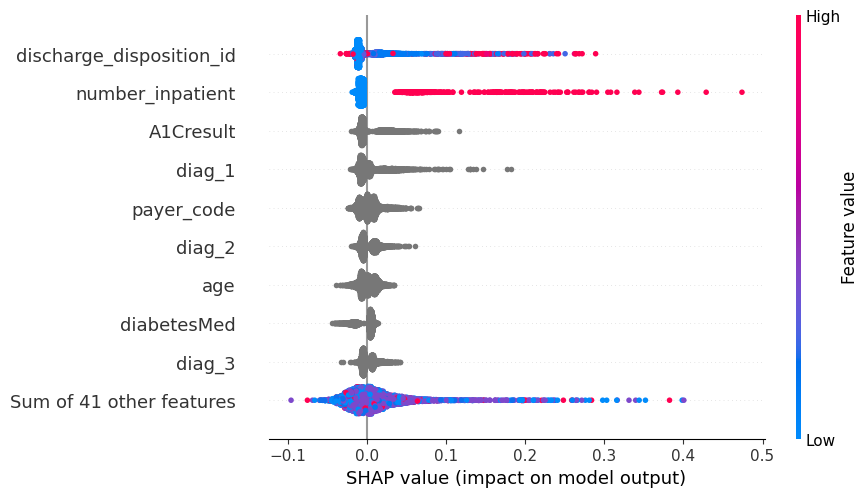

In [25]:
import copy
#import numpy as np
#import shap

# 1. Kopie der SHAP-Werte erstellen, um die Originaldaten nicht zu überschreiben
shap_values_prob = copy.deepcopy(shap_values)

# Logistische Transformation: f(x) = 1 / (1 + exp(-x))
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Basiswahrscheinlichkeit berechnen (Durchschnittliche Vorhersage des Modells)
base_prob = sigmoid(shap_values.base_values)

# Gesamte Modellvorhersage auf Wahrscheinlichkeitsebene bringen
total_prob = sigmoid(shap_values.base_values + shap_values.values.sum(axis=1))

# Die SHAP-Werte (Auswirkungen) als Differenz im Wahrscheinlichkeitsraum neu verteilen
# (Dies ist eine gängige Approximation für globale Plots)
for i in range(shap_values.values.shape[0]):
    diff = total_prob[i] - base_prob[i]
    total_log_odds_impact = shap_values.values[i].sum()
    
    if total_log_odds_impact != 0:
        # Verhältnismäßige Aufteilung des Wahrscheinlichkeitssprungs auf die Features
        shap_values_prob.values[i] = shap_values.values[i] * (diff / total_log_odds_impact)
    else:
        shap_values_prob.values[i] = 0

# 4. Den transformierten Beeswarm-Plot zeichnen
shap.plots.beeswarm(shap_values_prob)

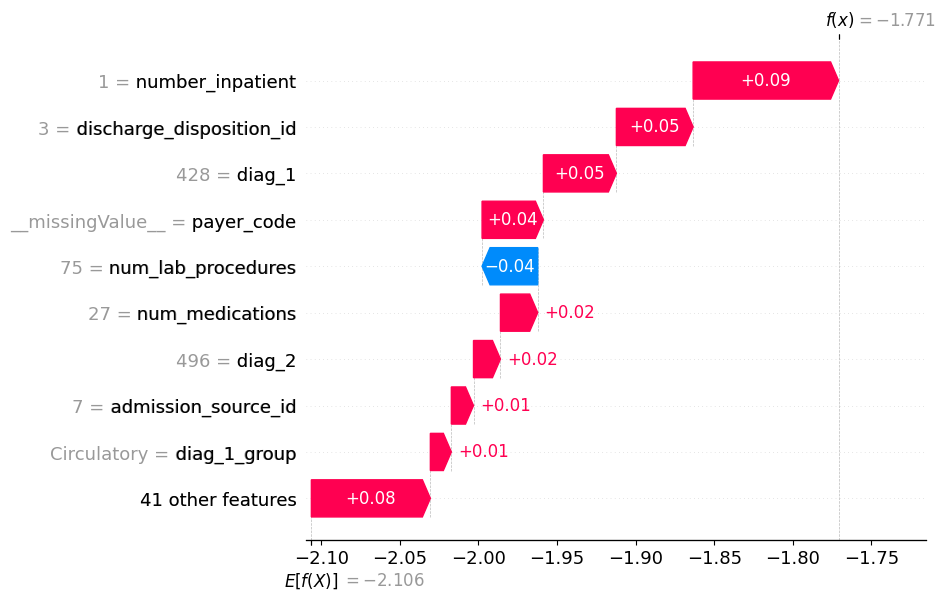

In [26]:
# 5. Local analysis: Waterfall plot for first data set:
shap.plots.waterfall(shap_values_prob[0])

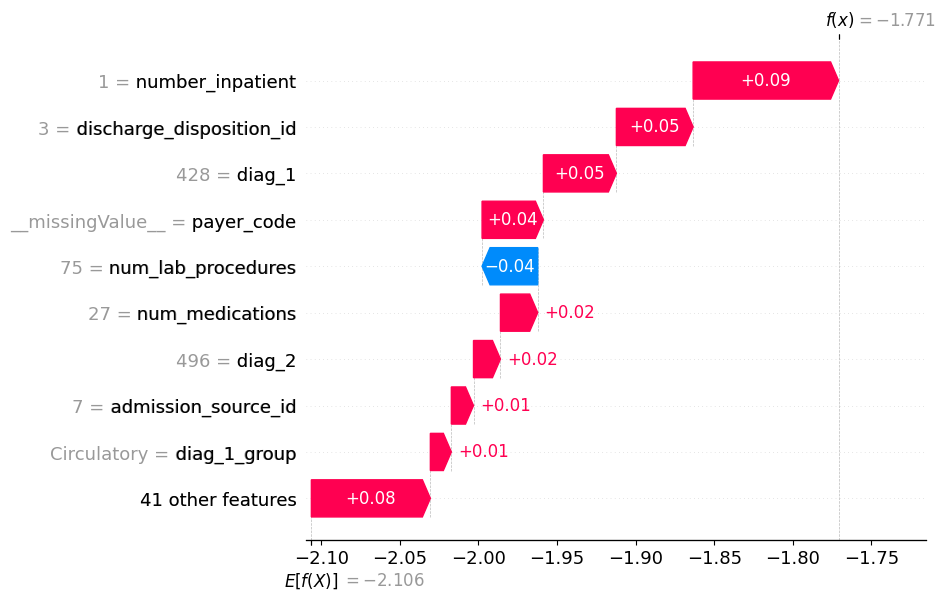

In [27]:
# 5. Local analysis: Waterfall plot for first data set (%-scale):
shap.plots.waterfall(shap_values_prob[0])

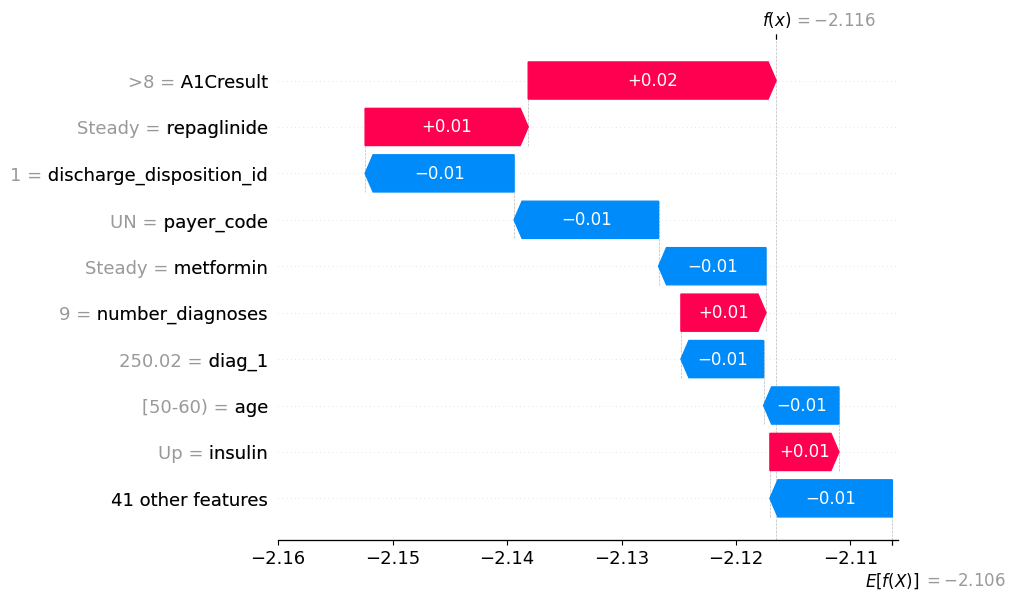

In [28]:
# other example (Logit-scale)
shap.plots.waterfall(shap_values_prob[3])

<h1 id="a03"
    style="font-size:18px; font-weight:bold;">
    3. Hyperparameter Optimization in CatBoost
    <a class="anchor-link"
       href="#a09"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

Now we want to investigate whether we can optimize the learning rate and tree depth of CatBoost by performing a costly cross-validated randomized search (fitting 40 models). 

In the first code block, we are setting the stage for hyperparameter optimization of the CatBoostClassifier model. We define a parameter grid specifying the range of values to be explored for the learning rate and the depth of the trees. Here, `loguniform` is used for the learning rate to sample from a logarithmic distribution, optimizing the search over different scales. Similarly, a list of integers represents possible values for the depth of the trees.

In [29]:
# define the hyperparameters grid to search
param_grid_CB ={'learning_rate': loguniform(0.005, 0.06), 
                'depth':         [4,5,6,7,8]}

# define variables for results reports
sel_params_CB = ['param_learning_rate','param_depth','mean_test_score','rank_test_score']

Following the initial setup, our next code block implements the actual hyperparameter optimization using RandomizedSearchCV, a strategy that randomly samples the parameter space and performs four-fold cross-validation. We choose a reasonable number of iterations (`n_iter=10`) to balance between computation time and thoroughness of the search. The results are captured, including the run time and the best parameters found.

In [30]:
# CatBoostClassifier: Hyper parameter optimization with RandomizedSearchCV
tic = time.time()

CB_rs = RandomizedSearchCV(CatBoostClassifier(iterations=2, eval_metric='AUC'), param_grid_CB,  #iterations=1000
                           cv=4, n_iter=10, n_jobs=-1, random_state=RANDOM_SEED, scoring='roc_auc')
CB_rs.fit(X_raw_train, y_train, cat_features=categorical_features, logging_level='Silent')

# Print the runtime as well as the five best hyper parameter constellations
print("time (sec):" + "%6.0f" % (time.time() - tic))
print("Best hyper parameters:",CB_rs.best_params_)
pd.DataFrame(CB_rs.cv_results_)[sel_params_CB].sort_values("rank_test_score").head()

time (sec):    18
Best hyper parameters: {'depth': 7, 'learning_rate': np.float64(0.03501197083814093)}


,param_learning_rate,param_depth,mean_test_score,rank_test_score
4,0.035012,7,0.569075,1
3,0.035745,8,0.563226,2
6,0.019131,8,0.563226,2
2,0.016452,8,0.563226,2
7,0.039551,5,0.563224,5


After identifying the best hyperparameters, we use them to fit a new CatBoostClassifier model with the entire training set. This approach leverages the optimized parameters that should theoretically yield a more accurate model.

In [31]:
# CatBoostClassifier: Fit new model on all folds (with best parameters) 
tic = time.time()
CB6 = CatBoostClassifier(**CB_rs.best_params_, iterations=2, eval_metric='AUC')   #, iterations=1000
CB6.fit(X_raw_train, y_train, cat_features=categorical_features, logging_level='Silent')
print("time (sec):" + "%6.0f" % (time.time() - tic))

time (sec):     1


Finally, we evaluate the performance of the tuned model by calculating the AUC score using the validation set.

In [32]:
# calculate and dispay the model AUC 
auc_CB6 = roc_auc_score(y_val, CB6.predict_proba(X_raw_val)[:,1])
print('The validation AUC of the CatBoost model with tuned hyperparameters is: {:.6f}'.format(auc_CB6))

The validation AUC of the CatBoost model with tuned hyperparameters is: 0.598722


Although it requires drastically more training time, the performance of the tuned model is unfortunately worse. 

<h1 id="a04"
    style="font-size:18px; font-weight:bold;">
    4. Data Preprocessing: Encoding and Scaling
    <a class="anchor-link"
       href="#a06"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

In this section, we concentrate on two essential preprocessing steps: encoding to make categorical data machine-readable, essential for many machine learning algorithms, and scaling to normalize the values of numerical features, aiding in algorithm efficiency.

<h2 style="font-size:16px; font-weight:bold;">4.1 Encoding categorical data and scaling numerical values</h2>

In general, machine learning models require input data to be in numerical format to perform mathematical computations. However, real-world datasets—such as the one considered here—frequently contain categorical or text data. Hence, encoding is needed to convert this non-numerical data into a numerical form that can be understood and processed by machine learning algorithms.

The two most commonly used encoding methods are the following:

- <u>Label-Encoding</u>: Converts each value in a column to a number. Good for ordinal data, i.e., when categories have an inherent order.

- <u>One-Hot-Encoding</u>: Creates a binary column for each category/label present in the column. This is useful for nominal variables, where the categories don't have any order or priority.

In the following, we will apply One-Hot-Encoding to our dataset in order to make it processable for machine learning methods such as Artificial Neural Nets or XGBoost.

In [33]:
# output the dimensions of the dataset prior to dummy encoding
print("Shape of the dataset before dummy encoding: ", df_raw.shape) 

# perform dummy encoding on categorical features, removing the first level to avoid dummy variable trap
df = pd.get_dummies(df_raw, drop_first=True)

# output the dimensions of the dataset after dummy encoding to show the change
print("Shape of the dataset after dummy encoding: ", df.shape)

Shape of the dataset before dummy encoding:  (47751, 51)
Shape of the dataset after dummy encoding:  (47751, 2256)


In [34]:
# change columns names (LightGBM does not support special JSON characters in feature names)
new_names = {col: re.sub(r'[^A-Za-z0-9_]+', '', col) for col in df.columns}
new_n_list = list(new_names.values())
new_names = {col: f'{new_col}_{i}' if new_col in new_n_list[:i] else new_col for i, (col, new_col) in enumerate(new_names.items())}
df = df.rename(columns=new_names)
df.head(1)

,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,TARGET,race_Asian,race_Caucasian,race_Hispanic,race_Other,race___missingValue__,gender_Male,gender___missingValue__,age_1020,age_2030,age_3040,age_4050,age_5060,age_6070,age_7080,age_8090,age_90100,weight_100125,weight_125150,weight_150175,weight_175200,weight_2550,weight_5075,weight_75100,weight___missingValue__,payer_code_CH,payer_code_CM,payer_code_CP,payer_code_DM,payer_code_FR,payer_code_HM,payer_code_MC,payer_code_MD,payer_code_MP,payer_code_OG,payer_code_OT,payer_code_PO,payer_code_SI,payer_code_SP,payer_code_UN,payer_code_WC,payer_code___missingValue__,medical_specialty_Anesthesiology,medical_specialty_AnesthesiologyPediatric,medical_specialty_Cardiology,medical_specialty_CardiologyPediatric,medical_specialty_DCPTEAM,medical_specialty_Dentistry,medical_specialty_EmergencyTrauma,medical_specialty_Endocrinology,medical_specialty_EndocrinologyMetabolism,medical_specialty_FamilyGeneralPractice,medical_specialty_Gastroenterology,medical_specialty_Gynecology,medical_specialty_Hematology,medical_specialty_HematologyOncology,medical_specialty_Hospitalist,medical_specialty_InfectiousDiseases,medical_specialty_InternalMedicine,medical_specialty_Nephrology,medical_specialty_Neurology,medical_specialty_Neurophysiology,medical_specialty_ObstericsGynecologyGynecologicOnco,medical_specialty_Obstetrics,medical_specialty_ObstetricsandGynecology,medical_specialty_Oncology,medical_specialty_Ophthalmology,medical_specialty_Orthopedics,medical_specialty_OrthopedicsReconstructive,medical_specialty_Osteopath,medical_specialty_Otolaryngology,medical_specialty_OutreachServices,medical_specialty_Pathology,medical_specialty_Pediatrics,medical_specialty_PediatricsCriticalCare,medical_specialty_PediatricsEmergencyMedicine,medical_specialty_PediatricsEndocrinology,medical_specialty_PediatricsHematologyOncology,medical_specialty_PediatricsNeurology,medical_specialty_PediatricsPulmonology,medical_specialty_Perinatology,medical_specialty_PhysicalMedicineandRehabilitation,medical_specialty_PhysicianNotFound,medical_specialty_Podiatry,medical_specialty_Proctology,medical_specialty_Psychiatry,medical_specialty_PsychiatryAddictive,medical_specialty_PsychiatryChildAdolescent,medical_specialty_Psychology,medical_specialty_Pulmonology,medical_specialty_Radiologist,medical_specialty_Radiology,medical_specialty_Rheumatology,medical_specialty_Speech,medical_specialty_Surgeon,medical_specialty_SurgeryCardiovascular,medical_specialty_SurgeryCardiovascularThoracic,medical_specialty_SurgeryColonRectal,medical_specialty_SurgeryGeneral,medical_specialty_SurgeryMaxillofacial,medical_specialty_SurgeryNeuro,medical_specialty_SurgeryPediatric,medical_specialty_SurgeryPlastic,medical_specialty_SurgeryThoracic,medical_specialty_SurgeryVascular,medical_specialty_SurgicalSpecialty,medical_specialty_Urology,medical_specialty___missingValue__,diag_1_11,diag_1_110,diag_1_112,diag_1_115,diag_1_117,diag_1_133,diag_1_135,diag_1_136,diag_1_141,diag_1_142,diag_1_143,diag_1_146,diag_1_147,diag_1_149,diag_1_150,diag_1_151,diag_1_152,diag_1_153,diag_1_154,diag_1_155,diag_1_156,diag_1_157,diag_1_158,diag_1_160,diag_1_161,diag_1_162,diag_1_163,diag_1_164,diag_1_170,diag_1_171,diag_1_172,diag_1_173,diag_1_174,diag_1_175,diag_1_179,diag_1_180,diag_1_182,diag_1_183,diag_1_184,diag_1_185,diag_1_187,diag_1_188,diag_1_189,diag_1_191,diag_1_192,diag_1_193,diag_1_194,diag_1_195,diag_1_196,diag_1_197,diag_1_198,diag_1_199,diag_1_200,diag_1_201,diag_1_202,diag_1_203,diag_1_204,diag_1_205,diag_1_207,diag_1_208,diag_1_210,diag_1_211,diag_1_212,diag_1_214,diag_1_215,diag_1_216,diag_1_218,diag_1_219,diag_1_220,diag_1_223,diag_1_225,diag_1_226,diag_1_227,diag_1_228,diag_1_229,diag_1_230,diag_1_233,diag_1_235,diag_1_236,diag_1_237,diag_1_238,diag_1_239,diag_1_240,diag_1_241,diag_1_242,diag_1_244,diag_1_245,

In [35]:
# generate the samples once again

# split dataset in 70% training, 15% validation and 15% test and devide into feature matrix x and label y
X = df.drop(['TARGET'], axis=1)
y = df.TARGET
X_train, X_valtest, y_train, y_valtest = train_test_split(X, y, train_size=0.70, random_state=RANDOM_SEED)
X_val, X_test, y_val, y_test = train_test_split(X_valtest, y_valtest, test_size=0.50, random_state=RANDOM_SEED)
print('Sample sizes for training, validation and test: ', X_train.shape, X_val.shape, X_test.shape)

Sample sizes for training, validation and test:  (33425, 2255) (7163, 2255) (7163, 2255)


Scaling is vital in machine learning for consistency, improved performance, and meeting algorithm requirements:

1. <u>Uniformity</u>: Diverse features can have varying scales, such as age ranging from 0 to 100 and income spanning thousands to millions. This can mislead algorithms into overemphasizing features with larger ranges.

2. <u>Efficiency</u>: Algorithms such as Gradient Descent and K-Nearest-Neighbors (KNN) benefit from features on a similar scale, resulting in better performance and quicker convergence. For example, KNN is heavily influenced by features with larger magnitudes.

3. <u>Normalization Requirement</u>: Certain machine learning algorithms, such as neural networks, require inputs to be scaled for model training to effectively proceed.

Typical scaling techniques include Min-Max Scaling, which adjusts features to a 0 to 1 range, and Standard Scaling, which sets features to zero mean and unit variance. The appropriate scaling approach is contingent upon the algorithm utilized and data characteristics. We will employ Standard Scaling in our analysis.

In [36]:
# generate list: feature names  
feature_names=list(X.columns)

# feature scaling using StandardScaler based on training data distributions 
scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns = feature_names)
X_val = pd.DataFrame(scaler.transform(X_val), columns = feature_names)

<h2 style="font-size:16px; font-weight:bold;">4.2 Do encoding and scaling affect the benchmark model?</h2>

In [37]:
# repeat CB with one-hot-encoded and scaled data
start_time = time.time()

CB4 = CatBoostClassifier(eval_metric='AUC', random_seed=RANDOM_SEED) 
CB4.fit(X_train, y_train,logging_level='Silent') # cat_features=selected_categorical_features, 

# calculate and print the running time in seconds
elapsed_time_CB4 = time.time() - start_time
print(f"Elapsed time (sec): {elapsed_time_CB4:.2f}")

Elapsed time (sec): 18.08


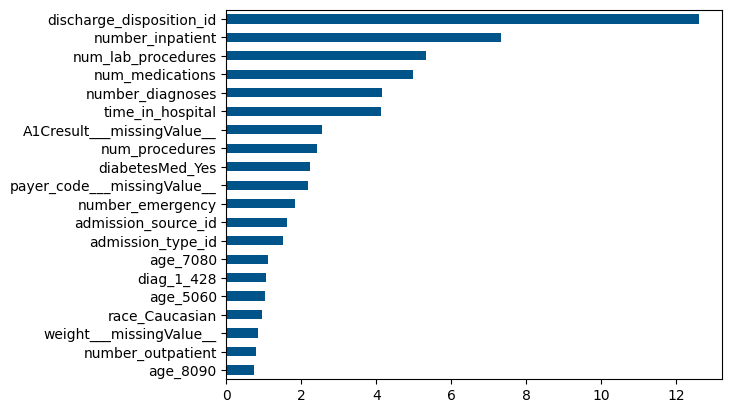

In [38]:
# CatBoost: Plot most the top 20 most important features
pd.Series(CB4.feature_importances_, index=X_train.columns).nlargest(20).plot(kind='barh', color=COLOR_DARK).invert_yaxis()
plt.show()

In [39]:
# calculate and dispay the model AUC  
auc_CB4 = roc_auc_score(y_val, CB4.predict_proba(X_val)[:,1])
print('The validation AUC of the CatBoost model after encoding and scaling is:   {:.6f}'.format(auc_CB4))
print('The validation AUC of the CatBoost model before (Part A, quick & easy):   {:.6f}'.format(auc_CB1))

The validation AUC of the CatBoost model after encoding and scaling is:   0.705952
The validation AUC of the CatBoost model before (Part A, quick & easy):   0.715503


In [40]:
print(f"Elapsed time of the CatBoost model after encoding and scaling (sec):  {elapsed_time_CB4:.2f}")
print(f"Elapsed time of the CatBoost model before. Part A, quick & easy (sec):  {elapsed_time_CB1:.2f}")

Elapsed time of the CatBoost model after encoding and scaling (sec):  18.08
Elapsed time of the CatBoost model before. Part A, quick & easy (sec):  129.30


**Summary and interpretation**: Although the encoding of the categorical data almost doubled the number of features (126 before vs. 239 after encoding), the training time of CatBoost decreased substancially while the AUC level decreased just slighly. Apparently, the direct use of the categorical features within CatBoost leads to a greatly increased computational effort, which, however, only leads to a minimal improvement in the prediction quality.

<h1 id="a05"
    style="font-size:18px; font-weight:bold;">
    5. Neural Networks (PyTorch)
    <a class="anchor-link"
       href="#a04"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>


#### a) Feed-Forward Neural Network with embeddings

In [41]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import math

from sklearn.preprocessing import LabelEncoder

In [42]:
# step 1 – preparing the data with special respect to reencoding all categorical features:

categorical_cols = [
   # "diag_1", "diag_2", "diag_3",
    "diag_1_group", "diag_2_group", "diag_3_group",
    "medical_specialty",
    "discharge_disposition_id",
    "age",
    "race"
]

encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df_raw[col] = le.fit_transform(df_raw[col].astype(str))
    encoders[col] = le


# List of selected numerical features to analyze
selected_numerical_features = ['number_outpatient', 'number_inpatient', 'num_procedures',
                               'num_lab_procedures','num_medications', 'time_in_hospital',
                               'number_emergency', 'number_diagnoses']

# further adaptions
numeric_cols = selected_numerical_features

# create a new dataframe using only a reduced set of variables
df_le = df_raw[numeric_cols + categorical_cols + ['TARGET']].copy()
print(df_le.shape)
df_le.head(3)

(47751, 16)


,number_outpatient,number_inpatient,num_procedures,num_lab_procedures,num_medications,time_in_hospital,number_emergency,number_diagnoses,diag_1_group,diag_2_group,diag_3_group,medical_specialty,discharge_disposition_id,age,race,TARGET
0,0,0,6,77,33,8,0,8,0,4,2,3,0,5,2,1
1,0,0,1,49,11,2,0,3,5,7,1,59,0,5,2,0
2,0,0,2,68,23,4,0,9,4,8,7,17,14,8,2,0


In [43]:
# resampling:

# separate the features (X) and the target (y) after preprocessing
X_le = df_le.drop(['TARGET'], axis=1)
y_le = df_le['TARGET']

# split the preprocessed dataset into a training set and a combined validation and test set
X_le_train, X_le_val_test, y_le_train, y_le_val_test = train_test_split(X_le, y_le, train_size=TRAIN_RATIO, random_state=RANDOM_SEED)

# further split the combined validation and test set into separate validation and test sets
X_le_val, X_le_test, y_le_val, y_le_test = train_test_split(X_le_val_test, y_le_val_test, test_size=VAL_TEST_RATIO, random_state=RANDOM_SEED)

# verify the dimensions of the training, validation, and test sets by displaying (rows, columns)
print(f"Preprocessed training set dimensions (rows, columns):   {X_le_train.shape}")
print(f"Preprocessed validation set dimensions (rows, columns): {X_le_val.shape}")
print(f"Preprocessed test set dimensions (rows, columns):       {X_le_test.shape}")

Preprocessed training set dimensions (rows, columns):   (33425, 15)
Preprocessed validation set dimensions (rows, columns): (7163, 15)
Preprocessed test set dimensions (rows, columns):       (7163, 15)


In [44]:
# rearranging the new dataframe
train_df = X_le_train.copy()
train_df['TARGET'] = y_le_train

val_df = X_le_val.copy()
val_df['TARGET'] = y_le_val 

In [45]:
# step 2 – defining a new class

class TabularDataset(Dataset):
    def __init__(self, df, categorical_cols, numeric_cols, target):
        self.cats = df[categorical_cols].values
        self.nums = df[numeric_cols].values.astype("float32")
        self.y = df[target].values.astype("float32")

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.cats[idx], dtype=torch.long),
            torch.tensor(self.nums[idx], dtype=torch.float32),
            torch.tensor(self.y[idx], dtype=torch.float32)
        )


In [46]:
# step 3 – neuronal net using embeddings

class TabularNN(nn.Module):
    def __init__(self, embedding_sizes, n_numeric):
        super().__init__()
        
        # Embedding layers
        self.embeddings = nn.ModuleList([
            nn.Embedding(num_categories, emb_dim)
            for num_categories, emb_dim in embedding_sizes
        ])
        
        total_emb_dim = sum([emb_dim for _, emb_dim in embedding_sizes])
        
        # MLP
        self.model = nn.Sequential(
            nn.Linear(total_emb_dim + n_numeric, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 1)
        )

    def forward(self, x_cats, x_nums):
        embedded = [emb(x_cats[:, i]) for i, emb in enumerate(self.embeddings)]
        x = torch.cat(embedded, dim=1)
        x = torch.cat([x, x_nums], dim=1)
        return self.model(x)


In [47]:
# step 4 – specifying embedding sizes

embedding_sizes = []

for col in categorical_cols:
    n_cat = df_raw[col].nunique()
    emb_dim = min(50, int(math.sqrt(n_cat) * 2))
    embedding_sizes.append((n_cat, emb_dim))
print(embedding_sizes)

[(10, 6), (10, 6), (10, 6), (67, 16), (21, 9), (10, 6), (6, 4)]


In [48]:
# step 5 – training

# start timer to calculate the running time of training the neural network
start_time = time.time()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TabularNN(embedding_sizes, len(numeric_cols)).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

train_dataset = TabularDataset(train_df, categorical_cols, numeric_cols, "TARGET")
val_dataset   = TabularDataset(val_df, categorical_cols, numeric_cols, "TARGET")

train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=1024)

EPOCHS = 50

for epoch in range(EPOCHS):
    model.train()
    for x_cat, x_num, y in train_loader:
        x_cat, x_num, y = x_cat.to(device), x_num.to(device), y.to(device)
        
        optimizer.zero_grad()
        outputs = model(x_cat, x_num).squeeze()
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch+1} done")

# calculate and print the running time in seconds
elapsed_time_NN = time.time() - start_time
print(f"Elapsed time (sec): {elapsed_time_NN:.2f}")

Epoch 1 done
Epoch 2 done
Epoch 3 done
Epoch 4 done
Epoch 5 done
Epoch 6 done
Epoch 7 done
Epoch 8 done
Epoch 9 done
Epoch 10 done
Epoch 11 done
Epoch 12 done
Epoch 13 done
Epoch 14 done
Epoch 15 done
Epoch 16 done
Epoch 17 done
Epoch 18 done
Epoch 19 done
Epoch 20 done
Epoch 21 done
Epoch 22 done
Epoch 23 done
Epoch 24 done
Epoch 25 done
Epoch 26 done
Epoch 27 done
Epoch 28 done
Epoch 29 done
Epoch 30 done
Epoch 31 done
Epoch 32 done
Epoch 33 done
Epoch 34 done
Epoch 35 done
Epoch 36 done
Epoch 37 done
Epoch 38 done
Epoch 39 done
Epoch 40 done
Epoch 41 done
Epoch 42 done
Epoch 43 done
Epoch 44 done
Epoch 45 done
Epoch 46 done
Epoch 47 done
Epoch 48 done
Epoch 49 done
Epoch 50 done
Elapsed time (sec): 73.08


In [49]:
# step 6 – evaluation (AUC)

model.eval()
preds = []
true = []

with torch.no_grad():
    for x_cat, x_num, y in val_loader:
        x_cat, x_num = x_cat.to(device), x_num.to(device)
        outputs = model(x_cat, x_num).squeeze()
        probs = torch.sigmoid(outputs).cpu().numpy()
        preds.extend(probs)
        true.extend(y.numpy())

auc_NN = roc_auc_score(true, preds)
print(f"Validation AUC (Neural Net): {auc_NN:.6f}")


Validation AUC (Neural Net): 0.677654


#### B) FT-Transformer (Gorishniy et al.)

In [50]:
# transformer block

class TransformerBlock(nn.Module):
    def __init__(self, d_token, n_heads, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(
            d_token, n_heads, dropout=dropout, batch_first=True
        )
        self.ffn = nn.Sequential(
            nn.Linear(d_token, d_token * 4),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_token * 4, d_token),
        )
        self.norm1 = nn.LayerNorm(d_token)
        self.norm2 = nn.LayerNorm(d_token)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + self.dropout(attn_out))
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))
        return x


In [51]:
# FT-Transformer

class FTTransformer(nn.Module):
    def __init__(
        self,
        embedding_sizes,
        n_numeric,
        d_token=32,
        n_heads=8,
        n_layers=4,
        dropout=0.2
    ):
        super().__init__()

        # Embeddings für kategoriale Features
        self.embeddings = nn.ModuleList([
            nn.Embedding(n_cat, d_token, max_norm=1.0)
            for n_cat, _ in embedding_sizes
        ])

        # Lineare Projektion numerischer Features → Tokens
        self.num_proj = nn.Linear(n_numeric, n_numeric * d_token)
        self.n_numeric = n_numeric
        self.d_token = d_token

        # CLS Token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_token))

        # Transformer Encoder
        self.blocks = nn.Sequential(*[
            TransformerBlock(d_token, n_heads, dropout)
            for _ in range(n_layers)
        ])

        # Output Head
        self.head = nn.Sequential(
            nn.LayerNorm(d_token),
            nn.Linear(d_token, 1)
        )

    def forward(self, x_cat, x_num):
        batch_size = x_cat.size(0)

        # Categorical → Embedding Tokens
        cat_tokens = [
            emb(x_cat[:, i]).unsqueeze(1)
            for i, emb in enumerate(self.embeddings)
        ]

        # Numeric → Tokens
        num_tokens = (
            self.num_proj(x_num)
            .view(batch_size, self.n_numeric, self.d_token)
        )

        # CLS Token
        cls = self.cls_token.expand(batch_size, -1, -1)

        # Alle Tokens zusammen
        x = torch.cat([cls] + cat_tokens + [num_tokens], dim=1)

        # Transformer
        x = self.blocks(x)

        # CLS → Prediction
        return self.head(x[:, 0]).squeeze()


In [52]:
##### Training 

# Start timer to calculate the running time of training the FT Transformer

start_time = time.time()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FTTransformer( embedding_sizes=embedding_sizes, n_numeric=len(numeric_cols), d_token=64, n_heads=8, n_layers=2, dropout=0.25 ).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

pos_weight = torch.tensor( [(len(y_train) - y_train.sum()) / y_train.sum()], device=device )

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Epoch loop

EPOCHS = 75

for epoch in range(EPOCHS): 
    model.train() 
    for x_cat, x_num, y in train_loader: x_cat, x_num, y = x_cat.to(device), x_num.to(device), y.to(device)

    optimizer.zero_grad()
    logits = model(x_cat, x_num)
    loss = criterion(logits, y)
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch+1}/{EPOCHS} done")

#Calculate and print the running time in seconds

elapsed_time_FT = time.time() - start_time 
print(f"Elapsed time (sec): {elapsed_time_FT:.2f}")

Epoch 1/75 done
Epoch 2/75 done
Epoch 3/75 done
Epoch 4/75 done
Epoch 5/75 done
Epoch 6/75 done
Epoch 7/75 done
Epoch 8/75 done
Epoch 9/75 done
Epoch 10/75 done
Epoch 11/75 done
Epoch 12/75 done
Epoch 13/75 done
Epoch 14/75 done
Epoch 15/75 done
Epoch 16/75 done
Epoch 17/75 done
Epoch 18/75 done
Epoch 19/75 done
Epoch 20/75 done
Epoch 21/75 done
Epoch 22/75 done
Epoch 23/75 done
Epoch 24/75 done
Epoch 25/75 done
Epoch 26/75 done
Epoch 27/75 done
Epoch 28/75 done
Epoch 29/75 done
Epoch 30/75 done
Epoch 31/75 done
Epoch 32/75 done
Epoch 33/75 done
Epoch 34/75 done
Epoch 35/75 done
Epoch 36/75 done
Epoch 37/75 done
Epoch 38/75 done
Epoch 39/75 done
Epoch 40/75 done
Epoch 41/75 done
Epoch 42/75 done
Epoch 43/75 done
Epoch 44/75 done
Epoch 45/75 done
Epoch 46/75 done
Epoch 47/75 done
Epoch 48/75 done
Epoch 49/75 done
Epoch 50/75 done
Epoch 51/75 done
Epoch 52/75 done
Epoch 53/75 done
Epoch 54/75 done
Epoch 55/75 done
Epoch 56/75 done
Epoch 57/75 done
Epoch 58/75 done
Epoch 59/75 done
Epoch 

In [53]:
# evaluation (AUC)

model.eval()
preds, true = [], []

with torch.no_grad():
    for x_cat, x_num, y in val_loader:
        x_cat, x_num = x_cat.to(device), x_num.to(device)
        logits = model(x_cat, x_num)
        probs = torch.sigmoid(logits).cpu().numpy()

        preds.extend(probs)
        true.extend(y.numpy())

auc_FT = roc_auc_score(true, preds)
print(f"Validation AUC (FT-Transformer): {auc_FT:.6f}")


Validation AUC (FT-Transformer): 0.628903


In [54]:
!pip install tab-transformer-pytorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
# import pandas as pd
# import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tab_transformer_pytorch import FTTransformer

# ---------------------------------------------------------
# 1. SYNTHETISCHE DATEN ERZEUGEN & VORBEREITEN
# ---------------------------------------------------------
# np.random.seed(42)
# n_samples = 1000

# Erzeuge kategoriale Spalten (z.B. Land, Abo-Typ, Gerät)
#cat_data = {
#    'land': np.random.choice(['DE', 'AT', 'CH'], size=n_samples),
#    'abo': np.random.choice(['Standard', 'Premium'], size=n_samples),
#    'device': np.random.choice(['Mobil', 'Desktop', 'Tablet'], size=n_samples)
#}
# Erzeuge numerische Spalten (z.B. Alter, Einkommen, Aktivität)
#num_data = {
#    'alter': np.random.randint(18, 70, size=n_samples).astype(np.float32),
#    'einkommen': np.random.uniform(20000, 80000, size=n_samples).astype(np.float32),
#    'tage_aktiv': np.random.exponential(scale=10, size=n_samples).astype(np.float32),
#    'score': np.random.normal(loc=50, scale=15, size=n_samples).astype(np.float32)
#}
# Zielvariable (0 oder 1)
# y = np.random.randint(0, 2, size=n_samples).astype(np.float32)

df_cat = pd.DataFrame(df_raw[categorical_cols])
df_num = pd.DataFrame(df_raw[numeric_cols])
y = pd.DataFrame(df_raw['TARGET'])

# Kategoriale Daten encodieren (0 bis Anzahl_Klassen - 1)
cat_encoders = {}
for col in df_cat.columns:
    le = LabelEncoder()
    df_cat[col] = le.fit_transform(df_cat[col])
    cat_encoders[col] = le

# Speichere die Kardinalität (Anzahl eindeutiger Werte) pro Kategorie
# Wichtig für das Modell-Setup!
categories_cardinality = tuple(df_cat.nunique().tolist()) # Ergebnis hier: (3, 2, 3)

# Numerische Daten standardisieren (Mittelwert=0, Varianz=1)
scaler = StandardScaler()
num_scaled = scaler.fit_transform(df_num)

X_cat = df_raw[categorical_cols].values
X_num = num_scaled
y = df_raw['TARGET'].values

X_cat_train, X_cat_temp, X_num_train, X_num_temp, y_train, y_temp = train_test_split(X_cat, X_num, y, train_size=TRAIN_RATIO, random_state=RANDOM_SEED)

# Dann den Rest in Val und Test aufteilen
X_cat_val, X_cat_test, X_num_val, X_num_test, y_val, y_test = train_test_split(X_cat_temp, X_num_temp, y_temp, test_size=VAL_TEST_RATIO, random_state=RANDOM_SEED)

# 5. Erst JETZT in PyTorch-Tensoren konvertieren & TensorDatasets erstellen
dataset_train = TensorDataset(
    torch.tensor(X_cat_train, dtype=torch.long),
    torch.tensor(X_num_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32).unsqueeze(1) # unsqueeze für Shape [Batch, 1]
)

dataset_val = TensorDataset(
    torch.tensor(X_cat_val, dtype=torch.long),
    torch.tensor(X_num_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
)

dataset_test = TensorDataset(
    torch.tensor(X_cat_test, dtype=torch.long),
    torch.tensor(X_num_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)
)

# 6. DataLoader erstellen
train_loader = DataLoader(dataset_train, batch_size=64, shuffle=True)
val_loader = DataLoader(dataset_val, batch_size=64, shuffle=False) # Val/Test meist shuffle=False
test_loader = DataLoader(dataset_test, batch_size=64, shuffle=False)

# ---------------------------------------------------------
# 2. FT-TRANSFORMER MODEL DEFINIEREN
# ---------------------------------------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = FTTransformer(
    categories = categories_cardinality, # Tuple mit Kategorien-Größen (3, 2, 3)
    num_continuous = X_num.shape[1], # Anzahl numerischer Spalten (4)
    dim = 32,                            # Interne Embedding-Dimension (Standard: 32)
    dim_out = 1,                         # 1 Ausgang für binäre Klassifikation
    depth = 4,                           # Anzahl der Transformer-Schichten (Blöcke)
    heads = 8,                           # Multi-Head Attention Köpfe
    attn_dropout = 0.1,                  # Dropout in der Attention-Schicht
    ff_dropout = 0.1                     # Dropout im Feed-Forward Netzwerk
).to(device)

# Loss und Optimizer definieren
criterion = nn.BCEWithLogitsLoss() # Perfekt für binäre Klassifikation (beinhaltet Sigmoid)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# ---------------------------------------------------------
# 3. TRAININGSSCHLEIFE (TRAINING LOOP)
# ---------------------------------------------------------
epochs = 5
model.train()

print(f"Starte Training auf {device}...\n")
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_cat, batch_num, batch_y in train_loader:
        # Daten auf das richtige Gerät verschieben (CPU oder GPU)
        batch_cat = batch_cat.to(device)
        batch_num = batch_num.to(device)
        batch_y = batch_y.to(device)
        
        # Gradienten zurücksetzen
        optimizer.zero_grad()
        
        # Forward Pass (FT-Transformer verlangt kategorial und numerisch getrennt)
        predictions = model(batch_cat, batch_num)
        
        # Loss berechnen
        loss = criterion(predictions, batch_y)
        
        # Backward Pass & Optimierung
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item() * batch_cat.size(0)
        
    total_epoch_loss = epoch_loss / len(train_loader.dataset)
    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_epoch_loss:.4f}")

print("\nTraining abgeschlossen!")



# evaluation (AUC)

model.eval()
preds, true = [], []

with torch.no_grad():
    for batch_cat, batch_num, batch_y in val_loader:
        batch_cat = batch_cat.to(device)
        batch_num = batch_num.to(device)
        batch_y = batch_y.to(device)
        
        #logits = model(batch_cat, batch_num)
        probs = model(batch_cat, batch_num) #torch.sigmoid(logits).cpu().numpy()

        preds.extend(probs)
        true.extend(batch_y.numpy())

auc_FTalternativ = roc_auc_score(true, preds)
print(f"Validation AUC (FT-Transformer alternativ): {auc_FTalternativ:.6f}")



Starte Training auf cpu...

Epoch 1/5 - Loss: 0.3749
Epoch 2/5 - Loss: 0.3660
Epoch 3/5 - Loss: 0.3647
Epoch 4/5 - Loss: 0.3635
Epoch 5/5 - Loss: 0.3622

Training abgeschlossen!
Validation AUC (FT-Transformer alternativ): 0.678293


<h2 style="font-size:16px; font-weight:bold;">5.2 Model evaluation and comparison</h2>

Prepare model comparison:

In [55]:
# data structures for model names and AUC
mname = []
mauc = []
dict = {'Model name': mname,'AUC': mauc, }

In [56]:
# store name and AUC of prevoisly fitted models 
mname.append("CB1_quick")
mauc.append(auc_CB1)
mname.append("NN_emb")
mauc.append(auc_NN)
mname.append("NN_FT-T")
mauc.append(auc_FT)
mname.append("NN_FT-T_alternativ")
mauc.append(auc_FTalternativ)

In [57]:
def plot_auc(d,x1,x2,t): 
    df_eval = pd.DataFrame(d)
    #sns.set_style('darkgrid')
    plt.title(" Model evaluation (AUC): " + t)
    sns.barplot(data = df_eval, x = "AUC", y = "Model name", color = COLOR_DARK)
    plt.xlim(x1, x2)
    plt.show()

Compare Model Performance (AUC - higher is better):

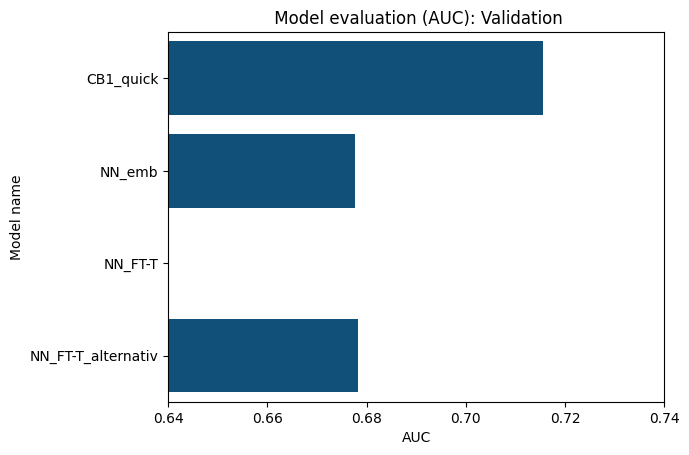

In [58]:
plot_auc(dict,0.64,0.74, "Validation")

The new features have noticeably improved the performance of our latest CatBoost model. Feature engineering can be the key to improving model performance. In a sense, our most important variables ext_source_* are also the result of (external) feature engineering. 

# <h2 style="font-size:16px; font-weight:bold;">6.1 Exporative Data Analysis</h2>

<h2 style="font-size:16px; font-weight:bold;">6.1 Analysis of categorical features</h2>

First, we examine a list of certain variables — age, gender, race, discharge_disposition_id as well as some medical variables — to gauge their influence on the likelihood of a readmission. Our analysis involves:

1. Creating stacked bar charts to contrast readmission counts and percentage distributions across different categories with respect to the target outcome.
2. Comparing the raw number of defaults to the proportion within each category to uncover potential predictive patterns.

By examining both the count and percentage distributions side by side, we can better understand how each examined feature correlates with the likelihood of a readmission encounter.

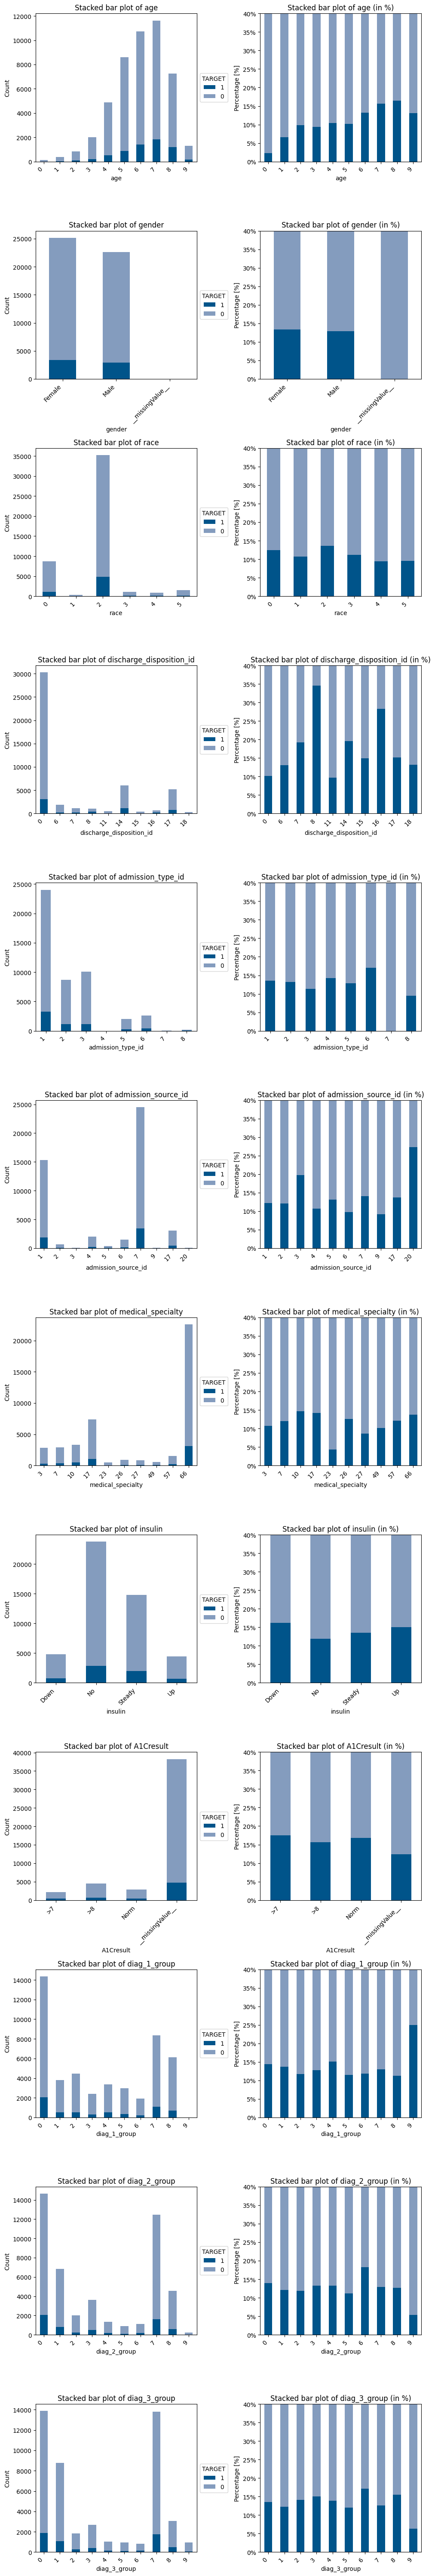

In [59]:
# List of selected categorical features to analyze
selected_categorical_features = ['age', 'gender', 'race', 'discharge_disposition_id', 
                                 'admission_type_id', 'admission_source_id', 
                                 'medical_specialty', 'insulin', 'A1Cresult', 
                                 'diag_1_group', 'diag_2_group', 'diag_3_group']

# Number of rows/columns for the subplot grid
n_cols = 2  # doubled to fit count and percentage plots side by side
n_rows = len(selected_categorical_features)  # one row for each feature

# Set up the matplotlib figure
plt.figure(figsize=(n_cols * 5, n_rows * 5))

# Loop through the number of categorical features
for idx, feature in enumerate(selected_categorical_features):
    # keep only top 10 categories
    top10 = df_raw[feature].value_counts().nlargest(10).index
    df_temp = df_raw[df_raw[feature].isin(top10)]
    
    # Create a crosstab for stacked bar plot structure
    ctab = pd.crosstab(df_temp[feature], df_temp['TARGET'])
    ctab = ctab[[1, 0]]  # TARGET=1 at bottom  
    
    # (1st column) add a new subplot iteratively for count values
    ax1 = plt.subplot(n_rows, n_cols, idx * n_cols + 1) 
    
    # Create a stacked bar plot for count values
    ctab.plot(kind="bar", stacked=True, color=[COLOR_DARK, COLOR_LIGHT], edgecolor="none", ax=ax1)
    
    # Additional plot settings for count subplot
    ax1.set_title(f'Stacked bar plot of {feature}')
    ax1.set_xlabel(feature)
    ax1.set_ylabel('Count')
    ax1.legend(title='TARGET', loc='center left', bbox_to_anchor=(1, 0.5))
    plt.xticks(rotation=45, ha='right')
    
    # (2nd column) add a new subplot iteratively for percentage values
    ax2 = plt.subplot(n_rows, n_cols, idx * n_cols + 2)
    
    # Normalize the crosstab by row and multiply by 100 to convert to percentages
    ctab_normalized = ctab.div(ctab.sum(axis=1), axis=0) * 100
    
    # Create a stacked bar plot for percentage values
    ctab_normalized.plot(kind="bar", stacked=True, color=[COLOR_DARK, COLOR_LIGHT], edgecolor="none", ax=ax2)
    
    # Additional plot settings for percentage subplot
    ax2.set_title(f'Stacked bar plot of {feature} (in %)')
    ax2.set_xlabel(feature)
    ax2.set_ylabel('Percentage [%]')
    ax2.legend().remove()
    plt.xticks(rotation=45, ha='right')
    
    # Make yticks be in percentages for the percentage subplot
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.0f}%".format(int(x))))
    ax2.set_ylim(0, 40)
    
# Preventing subplots from being too close to each other and display the final plot
plt.tight_layout()
plt.show()

Insights from the this feature analysis suggest:

Unsurprisingly the likelihood of a readmission encounter increases with age. There are some features showing for some values relatively high percentage scores regarding their procentual bar plots but this usually goes along with a very low case count. 
However some medical conditions, especially neoplasms or respiratory diseases, show higher readmission rates whilst having quite a lot of encounters of those types included in the dataset.

<h2 style="font-size:16px; font-weight:bold;">6.2 Analysis of numerical features</h2>

Next, we analyze some numerical variables occurring in the dataset. Through Kernel Density Estimation (KDE) plots, we observe the density distribution of each feature for both readmission and non readmission encounters. By comparing these distributions, we can identify which numerical predictors might have significant predictive power, a critical step for effective feature engineering and subsequent model building in binary classification tasks.

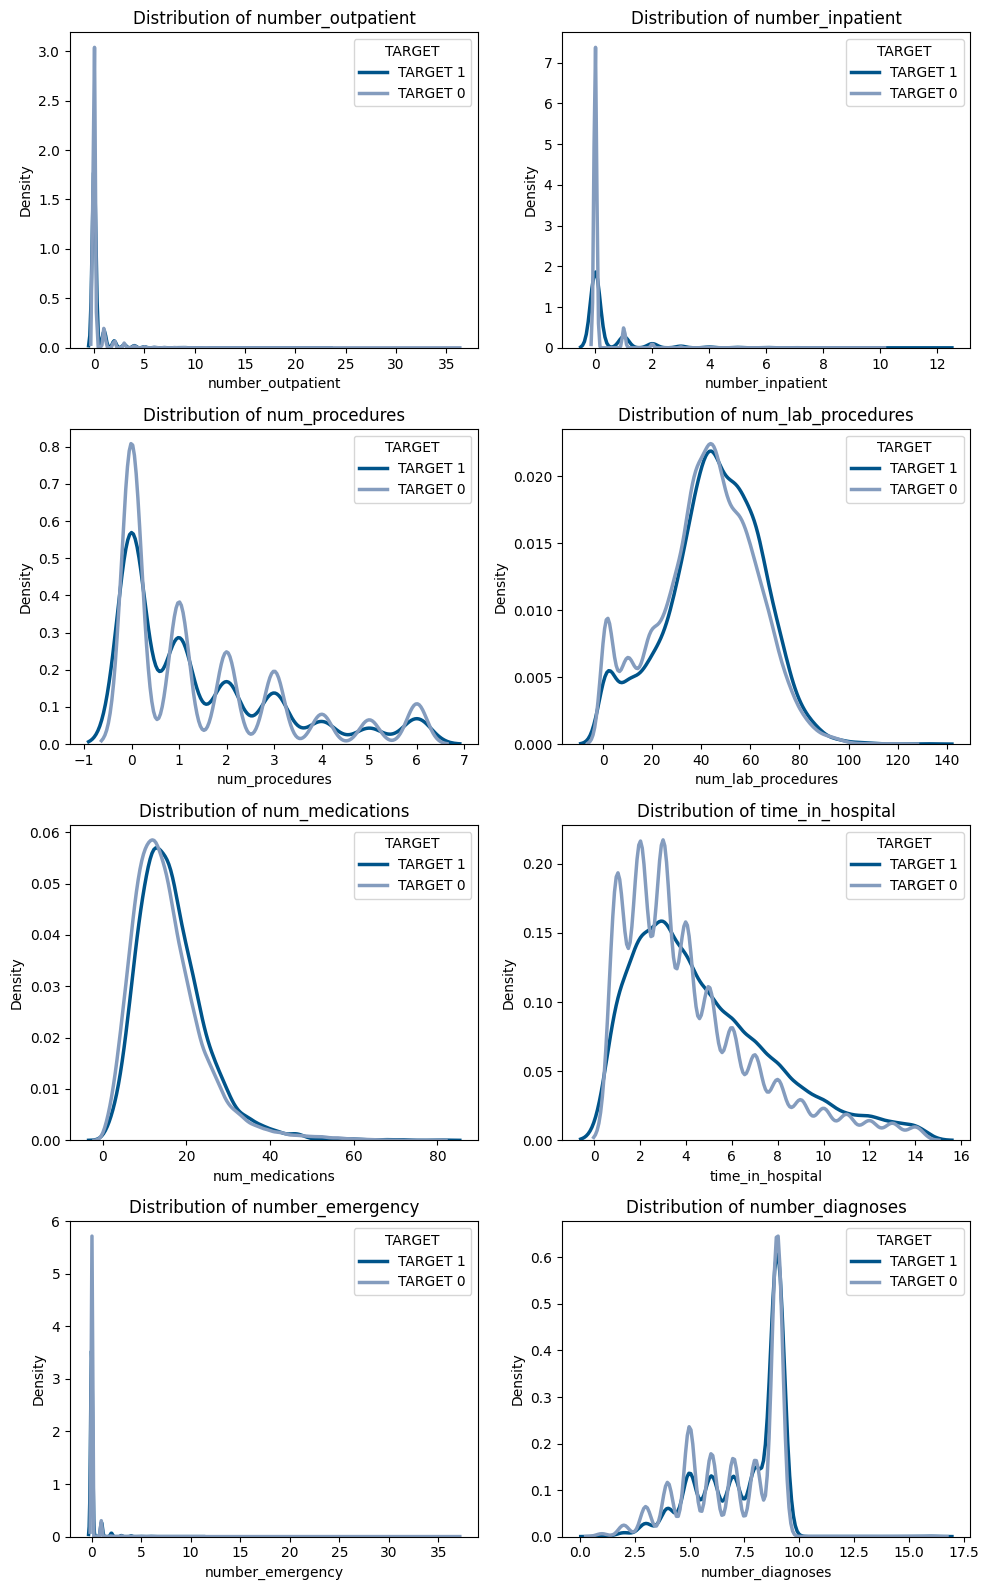

In [60]:
# List of selected numerical features to analyze
selected_numerical_features = ['number_outpatient', 'number_inpatient', 'num_procedures',
                               'num_lab_procedures','num_medications', 'time_in_hospital',
                               'number_emergency', 'number_diagnoses']

# number of plots, set up the subplot grid
n_plots = len(selected_numerical_features)
n_cols = 2  # adjust the number of columns based on your preference
n_rows = (n_plots + n_cols - 1) // n_cols

# set up the matplotlib figure
plt.figure(figsize=(n_cols * 5, n_rows * 4))

# loop through the list of numerical features
for idx, feature in enumerate(selected_numerical_features):
    ax = plt.subplot(n_rows, n_cols, idx + 1)
    
    # Create a color mapping based on TARGET values assuming values are 0 and 1
    color_mapping = {0: COLOR_LIGHT, 1: COLOR_DARK}
    
    class_vals = df_raw['TARGET'].unique()
    for val in class_vals:
        subset = df_raw[df_raw['TARGET'] == val]
        
        # Draw the KDE for each class
        sns.kdeplot(subset[feature], ax=ax, label=f'TARGET {val}', color=color_mapping[val], linewidth=2.5)
    
    # additional plot settings
    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(f'{feature}')
    ax.set_ylabel('Density')
    ax.legend(title='TARGET')

# Preventing subplots from being too close to each other and display the final plot
plt.tight_layout()
plt.show()

The analysis of these numerical features yields the following insights:

- `number_inpatient` seems to have a significant positive correlation with a possible readmission outcome 
- features like `num_procedures`, `num_lab_procedures`, `num_medications`, `time_in_hospital` or `number_diagnoses` also seem to have some kind of positive influence on the target variable  

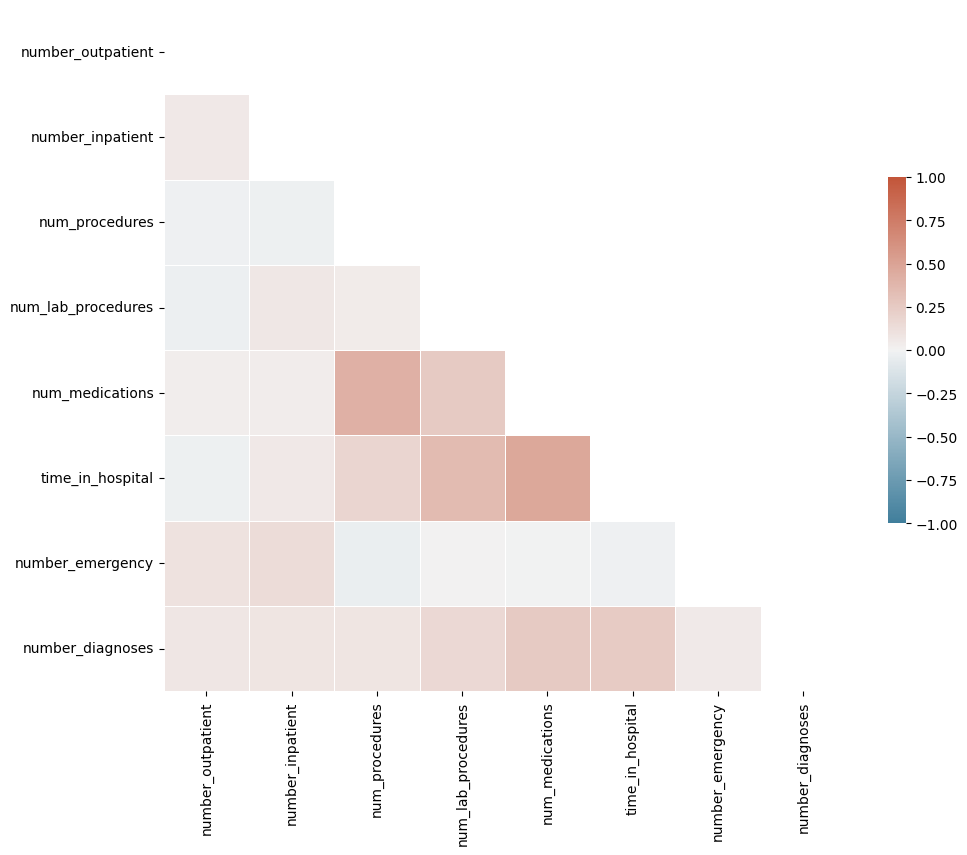

In [61]:
# Check correlations
feature_selection = ['number_outpatient', 'number_inpatient', 'num_procedures',
                               'num_lab_procedures','num_medications', 'time_in_hospital',
                               'number_emergency', 'number_diagnoses']

# Compute the correlation matrix
corr = df_raw[feature_selection].corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, center=0, vmax=1, vmin=-1,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.show()

<h1 id="a07"
    style="font-size:18px; font-weight:bold;">
    7. Logistic Regression: A Classical Approach to Classification
    <a class="anchor-link"
       href="#a02"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

In this section, we dive into logistic regression, a classical and foundational technique in binary classification tasks. Since this method cannot deal with missing feature values, we start by imputing missing numerical values by median values. We then implement and evaluate a low-parameter classical logistic regression model. Following this, we refit the CatBoost model based on the modified datasets, compare the new model's performance with that of the benchmark model and interpret the result.

<h2 style="font-size:16px; font-weight:bold;">7.1 Preparing the data: Imputing missing numbers with median</h2>

In this subsection, we address the challenge of missing data by imputing these missing values, an essential step since logistic regression requires complete datasets to accurately calculate predictions and model parameters. We have already imputed missing values for categorical features with a distinct category in Subsection 1.6. For numerical features, we choose the median due to its robustness to outliers and its effectiveness in preserving the distribution of skewed datasets. Although median imputation may reduce data variability and possibly introduce bias if the missing data is not random, its simplicity offers a practical approach for setting up a baseline model in binary classification tasks. The code snippet below demonstrates how we impute missing values in numerical features using the median calculated from the training data to prevent data leakage.

In [62]:
# Identify numerical features
numerical_features = list(X_raw_train.select_dtypes(exclude=['object']).columns)

# Copy the Input Data
df_pre = df_raw.copy()

# Replace missing values for numeric features by median value from the training data
for col in numerical_features:
    median_value = X_raw_train[col].median()
    df_pre[col] = df_pre[col].fillna(median_value)

# Check for remaining missing values:
num_missing = df_pre.isnull().sum().sum()
print(f"\nNumber of missing values after imputation: {num_missing}")


Number of missing values after imputation: 0


While our CatBoost model had no problems with very rare feature values, these initially prevented the upcoming logistic regression from converging. Therefore, we replace the extremely rare values with unknown gender (XNA) with the value “F”.

As performed previously in Subsection 1.4, we will proceed to divide our preprocessed dataset into separate training, validation, and testing sets accordingly. This crucial step, essential for training, fine-tuning, and evaluating our machine learning models, ensures that our model can be validated and tested on data that it has not seen during the training process.

In [63]:
# Constants for data split ratios
TRAIN_RATIO = 0.7
VAL_TEST_RATIO = 0.5  # Splitting the remaining 30% equally into validation and test

# Separate the features (X) and the target (y) after preprocessing
X_pre = df_pre.drop(['TARGET'], axis=1)
y_pre = df_pre['TARGET']

# Split the preprocessed dataset into a training set and a combined validation and test set
X_pre_train, X_pre_val_test, y_pre_train, y_pre_val_test = train_test_split(X_pre, y_pre, train_size=TRAIN_RATIO, random_state=RANDOM_SEED)

# Further split the combined validation and test set into separate validation and test sets
X_pre_val, X_pre_test, y_pre_val, y_pre_test = train_test_split(X_pre_val_test, y_pre_val_test, test_size=VAL_TEST_RATIO, random_state=RANDOM_SEED)

# Verify the dimensions of the training, validation, and test sets by displaying (rows, columns)
print(f"Preprocessed training set dimensions (rows, columns):   {X_pre_train.shape}")
print(f"Preprocessed validation set dimensions (rows, columns): {X_pre_val.shape}")
print(f"Preprocessed test set dimensions (rows, columns):       {X_pre_test.shape}")

Preprocessed training set dimensions (rows, columns):   (33425, 50)
Preprocessed validation set dimensions (rows, columns): (7163, 50)
Preprocessed test set dimensions (rows, columns):       (7163, 50)


<h2 style="font-size:16px; font-weight:bold;">7.2 Logistic regression implementation: Fitting and performance evaluation</h2>

Preparing for a logistic regression analysis that echoes R's formula-based modeling style, we merge the features and target variable into a single dataframe. This setup facilitates the use of statsmodels' formula API to define and fit the logistic regression model succinctly. Mindful of potential overfitting and convergence issues, we strategically select only the top 12 features out of the original 120, guided by their importance rankings determined by CatBoost in Subsection 1.5. Once the model has been fitted, we provide a comprehensive overview of the logistic regression results to facilitate interpretation and analysis.

In [64]:
# Combine features and target variable into a single dataframe for formula-based modeling
Xy_pre_train = X_pre_train.copy()
Xy_pre_train['TARGET'] = y_pre_train 

# Start timer to calculate the running time of training the logistic regression model
start_time = time.time()

# Define the logistic regression model using statsmodels' formula API and fit it to the training data
LR1 = smf.logit(formula="TARGET ~  C(discharge_disposition_id) + number_inpatient + diag_1_group + diag_2_group", 
                data=Xy_pre_train).fit() # maxiter=100

# Calculate and print the running time in seconds
elapsed_time_LR1 = time.time() - start_time
print(f"Elapsed time (sec): {elapsed_time_LR1:.2f}")

# Display a summary of the logistic regression model results
print(LR1.summary())

         Current function value: 0.365989
         Iterations: 35
Elapsed time (sec): 0.60
                           Logit Regression Results                           
Dep. Variable:                 TARGET   No. Observations:                33425
Model:                          Logit   Df Residuals:                    33401
Method:                           MLE   Df Model:                           23
Date:                Fri, 24 Jul 2026   Pseudo R-squ.:                 0.05456
Time:                        09:24:50   Log-Likelihood:                -12233.
converged:                      False   LL-Null:                       -12939.
Covariance Type:            nonrobust   LLR p-value:                1.712e-284
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -2.1640      0.033    -65.510      0

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Such a coefficient list can be the basis for the development of a classical credit score card, see this example https://de.mathworks.com/discovery/credit-scoring-model.html or Figure 1 in this research paper (2018): https://www.fico.com/blogs/fico-score-research-explainable-ai-credit-scoring. 

Now that our logistic regression model is trained, we evaluate its performance on the validation set by calculating the AUC, which provides us with a single metric summarizing the model's ability to discriminate between the positive and negative classes.

In [65]:
# Evaluate the performance of the logistic regression model on the validation data
# and calculate the Area Under the Curve (AUC) for the ROC
auc_LR1 = roc_auc_score(y_pre_val, LR1.predict(X_pre_val))

# Print the validation AUC
print(f'The validation AUC of the logistic regression model is: {auc_LR1:.6f}')

The validation AUC of the logistic regression model is: 0.643980


<h1 id="a08"
    style="font-size:18px; font-weight:bold;">
    8. Regularized Logistic Regression to Prevent Overfitting
    <a class="anchor-link"
       href="#a07"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

In order to prevent overfitting and avoid convergence problems, the classical logistic regression model in Subsection 3.2 was limited to some of the most important features based on prior knowledge (CatBoost feature importance). Now we are trying to improve this by using all features together with the concept of regularization. Regularized logistic regression is an extension of logistic regression in which a "penalty term" is added to the cost function. The penalty amount is usually determined by cross-validation and prevents the coefficients from becoming too large and leading to overfitting. L1 regularization (as in "LASSO") can result in some coefficients being set to zero, which is a form of feature selection, while L2 regularization (as in "Ridge Regression") results in the corresponding coefficients getting close to zero but not reaching exactly zero.

We use the scikit-learn `LogisticRegression` classifier and optimize the complexity parameter C, which is proportional to the inverse of the penalty. A very low C allows allmost no complexity and will shrink all coefficients towards 0, while a very high C can lead to the same result as the classical logistic regression with all features (i.e. no penalty). To avoid convergence problems when applying the logistic regression classifier, we have to restrict the tolerance parameter considerably, which means that we will probably not achieve the best results.

Since our dataset is quite large and we do have even much more credit default examples than encoded feautures, regularized logistic regression might hardly overfit. For educational purposes, we therefore perform the following steps twice, first with a small part and then with all preprocessed data (see 6.3).

# <h2 style="font-size:16px; font-weight:bold;">8.1 Regularized Logistic Regression models</h2>

Now we repeat the fitting procedures from above for the full samples processed in [Section 6](#a06).

In [66]:
tic = time.time()

# define lists to collect scores
train_scores_lasso, validation_scores_lasso, train_scores_ridge, validation_scores_ridge = list(), list(), list(), list()

# define the values of the regularization parameter to evaluate
Cs_lasso = np.logspace(-2.5, -1, 10)
Cs_ridge = np.logspace(-8, -2, 7)

# evaluate a logistic regression with L1 regularization for each value of C
print('Logistic regression with L1 regularization (Lasso-like): C, AUC train, AUC val.')
for c in Cs_lasso:
    # configure the model
    model = LogisticRegression(penalty='l1', C=c, tol=0.01, solver='saga')
    model.fit(X_train, y_train)
    # evaluate on the train and validation dataset
    train_scores_lasso.append(roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]))
    validation_scores_lasso.append(roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]))
    print('%.8f, train: %.4f, val.: %.4f, non-zero coefficients: %d' % (c, roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
                                             roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),
                                             np.sum(model.coef_.ravel() != 0)))

# evaluate a logistic regression with L2 regularization for each value of C
print('\nLogistic regression with L2 regularization (Ridge-like): C, AUC train, AUC val.')
for c in Cs_ridge:
    # configure the model
    model = LogisticRegression(penalty='l2', C=c, tol=0.01, solver='saga')
    model.fit(X_train, y_train)
    # evaluate on the train and validation dataset
    train_scores_ridge.append(roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]))
    validation_scores_ridge.append(roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]))
    print('%.8f, train: %.4f, val.: %.4f' % (c, roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]), 
                                             roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])))

print("\ntime (sec):" + "%6.0f" % (time.time() - tic))

Logistic regression with L1 regularization (Lasso-like): C, AUC train, AUC val.
0.00316228, train: 0.6674, val.: 0.6579, non-zero coefficients: 30
0.00464159, train: 0.6803, val.: 0.6658, non-zero coefficients: 55
0.00681292, train: 0.6933, val.: 0.6689, non-zero coefficients: 136
0.01000000, train: 0.7055, val.: 0.6731, non-zero coefficients: 300
0.01467799, train: 0.7210, val.: 0.6750, non-zero coefficients: 554
0.02154435, train: 0.7350, val.: 0.6742, non-zero coefficients: 900
0.03162278, train: 0.7453, val.: 0.6720, non-zero coefficients: 1253
0.04641589, train: 0.7521, val.: 0.6681, non-zero coefficients: 1604
0.06812921, train: 0.7561, val.: 0.6651, non-zero coefficients: 1813
0.10000000, train: 0.7582, val.: 0.6629, non-zero coefficients: 1966

Logistic regression with L2 regularization (Ridge-like): C, AUC train, AUC val.
0.00000001, train: 0.7246, val.: 0.6727
0.00000010, train: 0.7246, val.: 0.6726
0.00000100, train: 0.7250, val.: 0.6729
0.00001000, train: 0.7305, val.: 0.67

Plot training and validation AUC-scores vs regularization parameter:

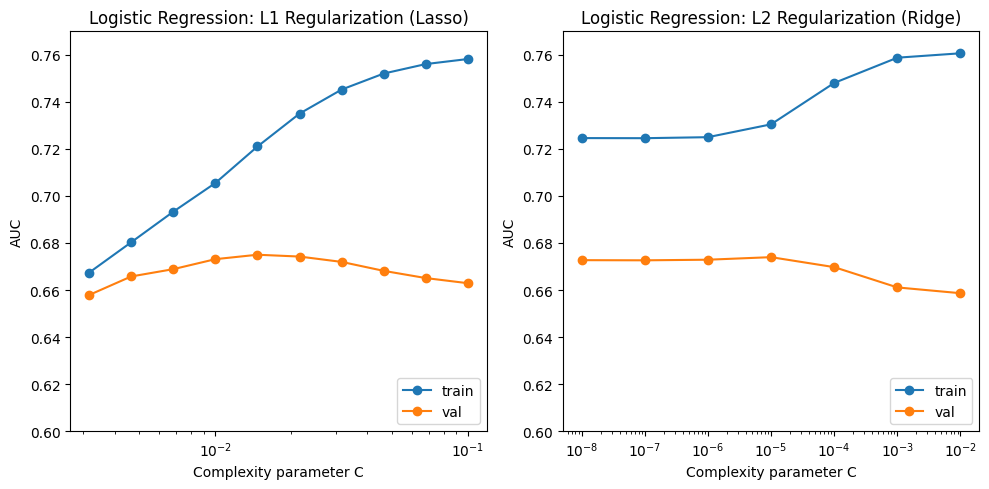

In [67]:
# create a figure consisting of two plots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# create the left plot on L1 regularization
ax1.plot(Cs_lasso, train_scores_lasso, '-o', label='Train')
ax1.plot(Cs_lasso, validation_scores_lasso, '-o', label='Validation')
ax1.set_xscale('log')
ax1.set_xlabel('Complexity parameter C')
ax1.set_ylim([0.6, 0.77])
ax1.set_ylabel('AUC')
ax1.set_title('Logistic Regression: L1 Regularization (Lasso)')
ax1.legend(['train', 'val'], loc='lower right')

# Create the right plot on L2 regularization
ax2.plot(Cs_ridge, train_scores_ridge, '-o', label='Train')
ax2.plot(Cs_ridge, validation_scores_ridge, '-o', label='Validation')
ax2.set_xscale('log')
ax2.set_xlabel('Complexity parameter C')
ax2.set_ylim([0.6, 0.77])
ax2.set_ylabel('AUC')
ax2.set_title('Logistic Regression: L2 Regularization (Ridge)')
ax2.legend(['train', 'val'], loc='lower right')

fig.tight_layout()
plt.show()

While we observe overfitting on the left-hand side, there is hardly none to be seen on the right-hand side of the diagrams (validation: orange). The best validation AUC is determined with L1 regularization and a C around 0.01. We therefore fit this model again and add the result to our model performance gallery:

The validation AUC of the L1 regularized logistic regression model is: 0.673176


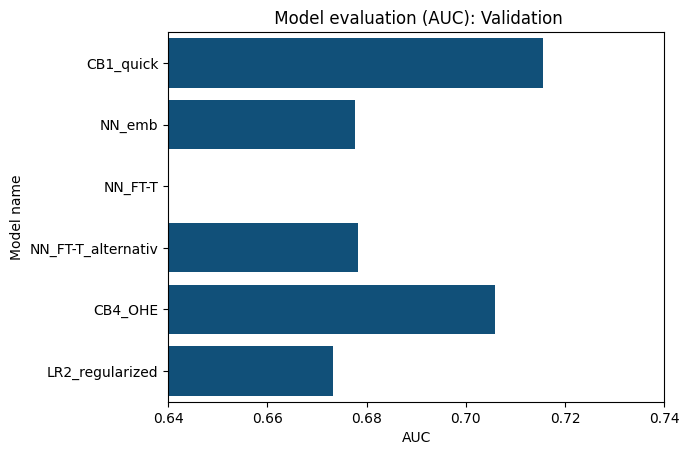

In [68]:
# fit the model with the best regularization parameters
LR2 = LogisticRegression(penalty='l1', C=0.01, tol=0.01, solver='saga')
LR2.fit(X_train, y_train)

# evaluate the performance of the logistic regression model on the validation data
auc_LR2 = roc_auc_score(y_val, LR2.predict_proba(X_val)[:, 1])

# print the validation AUC
print(f'The validation AUC of the L1 regularized logistic regression model is: {auc_LR2:.6f}')

# store name and AUC of prevoisly fitted models 
mname.append("CB4_OHE")
mauc.append(auc_CB4)
mname.append("LR2_regularized")
mauc.append(auc_LR2)

# compare AUC
plot_auc(dict, 0.64, 0.74, "Validation")

The L1 regularized logistic regression model with over 200 non-zero coefficients performs clearly better than the classic logistic regression using only twelve features but cannot keep up with our "quick and easy"-benchmark model. 

<h1 id="partc"
    style="font-size:22px; font-weight: 500; background-color: #E6E6E6; color: black; height: 50px; line-height: 46px; padding-left: 14px;">
    Part C: Tuning and Applying Machine Learning Models
    <a class="anchor-link"
       href="#partc"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
</h1>

<img src="https://i.postimg.cc/k4Gwhjk4/T-DALL-E-2023-10-24-22-42-17-Photo-of-an-intense-Olympic-100-meter-race-set-against-the-vastness-o.png" style="float: center; width: '100%'; max-width: '800px'">

Part C is all about harnessing the full potential of our models by fine-tuning hyperparameters for regularized logistic regression, artificial neural networks, and the gradient tree boosting model champions CatBoost, LightGBM, and XGBoost. We provide a detailed comparative evaluation using validation and test datasets and explore the application of these models in high-risk domains. To wrap up, we summarize the pivotal insights gleaned from our machine learning exploration. As we draw to a close, we reflect on the key learnings from our machine learning journey.

<h2 style="font-size:16px; font-weight:bold;">9 Automated Machine Learning with AutoGluon</h2>

In [75]:
#!pip install autogluon
# Install AutoGluon (only required if it is not already available
# in the Kaggle environment)
!pip install -q autogluon.tabular

# Import required libraries
from autogluon.tabular import TabularPredictor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score
)

# ============================================================
# Prepare training and test data
# ============================================================

# AutoGluon expects the target variable to be part of the
# training DataFrame. Therefore, the feature matrix and
# target variable are combined.

train_data = X_train.copy()
train_data["target"] = y_train

test_data = X_test.copy()
test_data["target"] = y_test


# ============================================================
# Train the AutoML model
# ============================================================

# TabularPredictor automatically performs:
# - feature engineering
# - model selection
# - hyperparameter optimization
# - ensemble construction

predictor = TabularPredictor(
    label="target",               # Name of the target column
    problem_type="binary",        # Binary classification task
    eval_metric="accuracy",       # Optimization metric
    path="autogluon_readmission"  # Directory to store trained models
).fit(
    train_data=train_data,
    presets="best_quality",       # Prioritize predictive performance
    time_limit=600                # Maximum training time (seconds)
)


# ============================================================
# Display model leaderboard
# ============================================================

# Show all trained models and their performance on the test set.

leaderboard = predictor.leaderboard(test_data, silent=True)
display(leaderboard)


# ============================================================
# Generate predictions
# ============================================================

# Predict the class labels (0 or 1) for the test set.

y_pred_ag = predictor.predict(X_test)


# ============================================================
# Evaluate model performance
# ============================================================

accuracy_ag = accuracy_score(y_test, y_pred_ag)
precision_ag = precision_score(y_test, y_pred_ag)
recall_ag = recall_score(y_test, y_pred_ag)

print(f"Accuracy : {accuracy_ag:.3f}")
print(f"Precision: {precision_ag:.3f}")
print(f"Recall   : {recall_ag:.3f}")


# ============================================================
# Compute confusion matrix
# ============================================================

# The confusion matrix summarizes the prediction results:
# TN = True Negatives
# FP = False Positives
# FN = False Negatives
# TP = True Positives

confusion_ag = confusion_matrix(y_test, y_pred_ag)
print(confusion_ag)

# evaluate the performance of the logistic regression model on the validation data
auc_auto = roc_auc_score(y_val, predictor.predict_proba(X_val).iloc[:, 1])
print(f"ROC AUC: {auc_auto:.3f}")

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.12
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Sat May 30 15:40:53 UTC 2026
CPU Count:          4
Pytorch Version:    2.10.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       26.96 GB / 31.35 GB (86.0%)
Disk Space Avail:   18.11 GB / 19.52 GB (92.8%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
DyStack is enabled (dynamic_stacking=True). AutoGluon will try to determine whether the input data is affected by stacked overfitting and enable or disable stacking as a consequence.
	This is used to identify the optimal `num_stack_levels` va

,model,score_test,score_val,eval_metric,pred_time_test,pred_time_val,fit_time,pred_time_test_marginal,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,CatBoost_BAG_L1,0.866816,0.871713,accuracy,0.849585,0.446416,47.524117,0.849585,0.446416,47.524117,1,True,3
1,WeightedEnsemble_L2,0.866816,0.871713,accuracy,0.852504,0.449001,47.741279,0.002919,0.002585,0.217162,2,True,7
2,RandomForestGini_BAG_L1,0.865838,0.869738,accuracy,0.919989,22.053768,43.128261,0.919989,22.053768,43.128261,1,True,1
3,RandomForestEntr_BAG_L1,0.865699,0.869768,accuracy,0.754922,21.726328,41.030108,0.754922,21.726328,41.030108,1,True,2
4,ExtraTreesGini_BAG_L1,0.865699,0.869858,accuracy,0.862638,22.174634,49.276454,0.862638,22.174634,49.276454,1,True,4
5,ExtraTreesEntr_BAG_L1,0.865699,0.869738,accuracy,0.873625,22.029064,45.163806,0.873625,22.029064,45.163806,1,True,5
6,XGBoost_BAG_L1,0.172553,0.870935,accuracy,2.542595,0.689599,56.807177,2.542595,0.689599,56.807177,1,True,6


Accuracy : 0.867
Precision: 0.600
Recall   : 0.025
[[6185   16]
 [ 938   24]]
ROC AUC: 0.693


<h1 id="a11"
    style="font-size:18px; font-weight:bold;">
    10. Model Evaluation and Application
    <a class="anchor-link"
       href="#a11"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

<h2 style="font-size:16px; font-weight:bold;">10.1 Model evaluation: Validation and test set</h2>

Now that the modeling is complete, it is time to evaluate our models on test data and compare the results with the validation data and between the different models of interest. We consider all tuned models and two untuned CatBoost models, first the baseline model (cb1) and finally the last and best non-tuned model (cb5).

In [70]:
# calulate model AUC based on test data 

auc_CB1_test = roc_auc_score(y_test, CB1.predict_proba(X_raw_test)[:, 1])
auc_LR1_test = roc_auc_score(y_test, LR1.predict(X_pre_test))

# feature scaling using StandardScaler based on training data distributions (6.1)
#X_test = pd.DataFrame(scaler.transform(X_test), columns = feature_names)

# calculate the model test AUC 
auc_LR2_test = roc_auc_score(y_test, LR2.predict_proba(X_test)[:,1])
# auc_ANN_test = roc_auc_score(y_test, ANN.predict_proba(X_test)[:,1])
auc_CB6_test = roc_auc_score(y_test, CB6.predict_proba(X_raw_test)[:,1])


In [71]:
# data structures for model names, val/test-sample and AUC
mdict = {'Model name': [], 'Set': [], 'AUC': []}

# list of models and their AUC scores on validation and test sets
models_auc = [
    ("LR1_select",      auc_LR1, auc_LR1_test),
    ("LR2_regularized", auc_LR2, auc_LR2_test),
    ("CB1_quick",       auc_CB1, auc_CB1_test),
    ("CB6_tuned",       auc_CB6, auc_CB6_test)
]

# populate the dictionary by looping over the models and their AUC scores
for model_name, auc_val, auc_test in models_auc:
    mdict['Model name'].extend([model_name] * 2)  # Model name twice for Val. and Test
    mdict['Set'].extend(["Val.", "Test"])
    mdict['AUC'].extend([auc_val, auc_test])

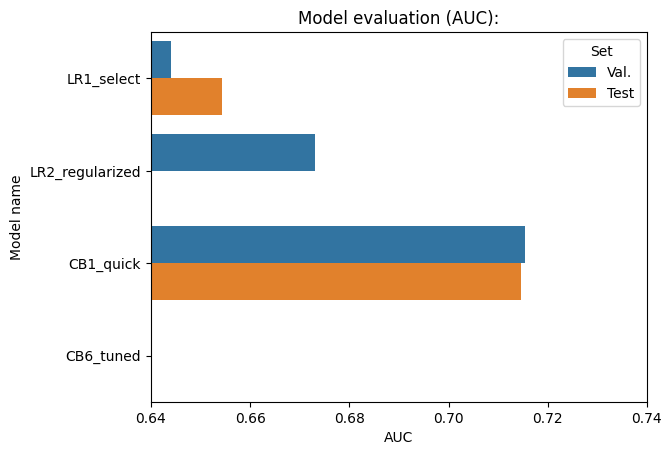

In [72]:
df_eval = pd.DataFrame(mdict)
plt.title("Model evaluation (AUC):")
sns.barplot(data=df_eval, x="AUC", y="Model name",hue="Set")
plt.xlim(0.64, 0.74)
plt.show()

Surprisingly, all models perform better on the test data. This could be due to differences in the samples and the corresponding TARGET distribution, as indicated in Subsection 1.3. 

The top three models for both samples are CB5_subsample (untuned). These models have benefited from feature engineering, which is the main reason why they perform better than our base model CB1_quick.

<h2 style="font-size:16px; font-weight:bold;">10.2 High risk prediction</h2>

In Subsection 11.1, we considered a model with the highest area under the Receiver Operating Characteristic Curve (AUC) to be the best based on all loan applications from low to high risk. Since the high-risk area usually receives the most attention for economic reasons, the performance of the models in this area is more decisive for the application. The lift chart is suitable for this evaluation. A cumulative lift chart shows the improvement that a model offers compared to a random estimate and measures the change in the form of a lift scores.

In [ ]:
# make preditions for test data
y_test_CB1 = CB1.predict_proba(X_raw_test)
y_test_LR2 = LR2.predict_proba(X_test)

In [ ]:
# Core of scikit-plot function cumulative_gain_curve (necessary, since scypi release 1.12.0 broke compatibility with scikit-plot version 0.3.7.
# Source: https://github.com/reiinakano/scikit-plot/blob/26007fbf9f05e915bd0f6acb86850b01b00944cf/scikitplot/helpers.py
def cumulative_gain_curve1(y_true, y_score):
    """This binary classification function generates the points necessary to plot the Cumulative Gain"""
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    # make y_true a boolean vector
    y_true = (y_true == 1)
    sorted_indices = np.argsort(y_score)[::-1]
    y_true = y_true[sorted_indices]
    gains = np.cumsum(y_true)
    percentages = np.arange(start=1, stop=len(y_true) + 1)
    gains = gains / float(np.sum(y_true))
    percentages = percentages / float(len(y_true))
    gains = np.insert(gains, 0, [0])
    percentages = np.insert(percentages, 0, [0])
    return percentages, gains

# calculate cumulative gains for lift chart 
def calculate_gains_and_percentages(model_predictions, y_true):
    """Calculate gains and percentages for a given model's predictions."""
    percentages, gains = cumulative_gain_curve1(y_true, model_predictions[:, 1])
    gains_adjusted = gains[1:] / percentages[1:]  # Adjust gains starting from the second element
    return percentages[1:], gains_adjusted


In [ ]:
# select models and prepare true and predicted values
y_true = np.array(np.ravel(y_test))
model_predictions = {
    'CB1_quick': np.array(y_test_CB1),
    'LR2_regularized': np.array(y_test_LR2)
}

# initialize lift chart
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_title("Lift chart for high risk area (top decile)")
ax.set_xlabel('Fraction of high risk credit applications')
ax.set_ylabel('Lift')
plt.xlim(0, 0.1)
plt.ylim(0, 8.0)

# calculate and plot lift score for each model
for label, predictions in model_predictions.items():
    percentages, gains_adjusted = calculate_gains_and_percentages(predictions, y_true)
    ax.plot(percentages, gains_adjusted, lw=2, label=label)

# plot random choice baseline
ax.plot([0, 1], [1, 1], 'k--', lw=2, label='random choice')
ax.legend(loc='upper right')
plt.show()

The cumulative lift chart shows the factor (lift score) by which the model can improve the "hit rate". 
For example, the special consideration of the 6% of applications with the highest probability of default, which have a lift score of 4.2, could already influence 25% of all credit defaults.

In our case, there is no clear winner model for the top decile. All gradient tree boosting models have a similar lift score. Thus, we can take our first "quick & easy" baseline model for defining the top risk area. In the following, we focus on the top decile and create a list of the riskiest loan applications. Since we know the true value for our test data, we compare it with the predicted values. 

In [ ]:
# merge predicted an true values into a DataFrame
df = pd.DataFrame({
    'PredProbability': y_test_CB1[:,1],
    'TrueValue': y_test
})

# sort by Probability in descending order
df_sorted = df.sort_values(by='PredProbability', ascending=False)
df_sorted.head()

In [ ]:
# creating a 'Percentile' column based on quantile-based discretization into 100 bins
df_sorted['Percentile'] = pd.qcut(df_sorted['PredProbability'], 100, labels=range(1, 101))

# calculate means of predicted and true values for the top 10 percentiles
percentile_means = df_sorted.groupby('Percentile', observed=True).mean().tail(10)

# printing the results for the top 10 percentiles
print(percentile_means[::-1])  # This reverses the order to start with the highest probabilities

Although the predicted probabilities seem a little too high, the ranking of percentiles works very well and can be used to decide on the actions to be taken, taking into account the associated quite different costs of lost business opportunities and credit losses.

<h1 id="a12"
    style="font-size:18px; font-weight:bold;">
    11. Key Insights into Model Performance and Binary Classification
    <a class="anchor-link"
       href="#a12"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

As we conclude our study on credit scoring with the Home Credit Default Risk dataset, we consolidate the key insights essential for actuaries tackling binary classification problems:

- <u>CatBoost</u>: CatBoost is characterized by the fact that it requires minimal preprocessing, manages categorical features natively, and produces high-quality results quickly and easily in our binary classification task.

- <u>Feature Engineering</u>: The task of enhancing our data through feature engineering proves to be exceptionally worthwhile. By devising financial ratios and relevant interactions among features, we observe a notable uplift in our model's AUC score. This underlines the importance of domain-specific insights in optimizing predictive models.

- <u>Hyperparameter Tuning</u>: While hyperparameter optimization does refine a model's performance, it is feature engineering that stands out as the more influential factor in our classification task. Nevertheless, when fine-tuning is applied to gradient boosting algorithms like LightGBM, we witness a discernible enhancement in model output, marking it as a noteworthy step in the model refinement process.

- <u>Subsampling</u>: Enriching the event rate from 8% to 25% by removing numerous non-events from the training data improves model balance between events and non-events, leading to slightly better predictive quality. This also significantly reduces training times, allowing for further tuning to enhance prediction accuracy.

These findings illustrate the synergy between machine learning techniques and sector-specific expertise, paving the way to more effective credit risk modeling.

<h1 id="partappendix"
    style="font-size:22px; font-weight: 500; background-color: #E6E6E6; color: black; height: 50px; line-height: 46px; padding-left: 14px;">
    Appendix
    <a class="anchor-link"
       href="#partappendix"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
</h1>

In the Appendix, we provide additional resources on CatBoost functionality, including comprehensive tutorials and practical examples of this machine learning algorithm. Following this, we offer a concise guide on preparing your system for GPU utilization—a crucial step for efficiently training LightGBM and XGBoost models, especially when conducting hyperparameter tuning.

<h1 id="a14"
    style="font-size:18px; font-weight:bold;">
    A1. Understanding CatBoost: Additional Resources and Reading
    <a class="anchor-link"
       href="#a14"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">    
 </h1>

Section A1 gathers some essential resources for understanding and implementing CatBoost, enhancing both theoretical knowledge and practical application.

- <u>Top Advantages of CatBoost</u>: Explore the key benefits that make CatBoost a preferred tool for data analysis, as highlighted by 'KDnuggets', focusing on its unique features and ease of use.<br> https://www.kdnuggets.com/2023/02/top-5-advantages-catboost-ml-brings-data-make-purr.html

- <u>Interpreting Models with SHAP and CatBoost</u>: Learn to interpret CatBoost models with SHAP values through a comprehensive tutorial that is indispensable for actuaries seeking transparency in their model predictions.<br>
https://shap.readthedocs.io/en/latest/example_notebooks/tabular_examples/tree_based_models/Catboost%20tutorial.html

- <u>Handling Categorical Data with CatBoost</u>: Dive into a tutorial from CatBoost's GitHub that guides you on effectively managing categorical data, which is crucial for leveraging the full power of the algorithm.<br>
https://github.com/catboost/catboost/blob/master/catboost/tutorials/categorical_features/categorical_features_parameters.ipynb

- <u>CatBoost's Approach to Missing Values</u>: Understand how CatBoost processes missing values with its `nan_mode` parameter, an essential part of data preparation that can affect overall model accuracy.<br>
https://catboost.ai/en/docs/concepts/algorithm-missing-values-processing

- <u>Practical CatBoost Example on Titanic Data</u>: Examine a hands-on example of applying CatBoost to the Titanic dataset on Kaggle to see how it performs in a real-world machine learning scenario.<br>
https://www.kaggle.com/code/manrunning/catboost-for-titanic-top-7

<h1 id="a15"
    style="font-size:18px; font-weight:bold;">
    A2. Fast Execution with GPU Usage
    <a class="anchor-link"
       href="#a15"
       target="_self"
       rel=" noreferrer nofollow">
    </a>
    <hr style="border: none; border-top: 3px solid black; margin-top: 10px;">
</h1>

        batch_cat = batch_cat.to(device)
        batch_num = batch_num.to(device)
        batch_y = batch_y.to(device)        batch_cat = batch_cat.to(device)
        batch_num = batch_num.to(device)
        batch_y = batch_y.to(device)In this section, we provide a concise How-To on integrating GPU acceleration into the machine learning workflow detailed previously:

1. Select your preferred accelerator via the notebook's options.
2. Activate GPU usage in GBM tools:
   - For LightGBM, add `device='gpu'` to the parameters list.
   - For XGBoost, add `device='cuda'` to the parameters list.
3. Prevent TensorFlow from fully allocating GPU memory:
TensorFlow is configured to claim all available GPU memory by default, which could be restrictive when also running GBM models. Therefore, we have to limit TensorFlow's GPU memory growth, see the guideline at https://www.tensorflow.org/guide/gpu#limiting_gpu_memory_growth.